# Akciğer Nodülü Malignite Sınıflandırması — 1. Veri, ön işleme, klasik bölütleme (v1) ve CNN

Görüntü İşleme dersi proje defteri. Google Colab (T4 GPU) üzerinde çalıştırıldı; hücreler çalıştırıldıkları sırayla ve çıktılarıyla birlikte duruyor. Ayrıntılı açıklama için `README.md`.

## Adım 1 — Etiket dosyasını indirme (Zenodo 14673658)

In [2]:
!wget -q -c https://zenodo.org/records/14673658/files/LUNA25_Public_Training_Development_Data.csv

import pandas as pd
df = pd.read_csv("LUNA25_Public_Training_Development_Data.csv")

print("Satır, sütun:", df.shape)
print("\nSütunlar:", list(df.columns))
df.head()

Satır, sütun: (6163, 12)

Sütunlar: ['PatientID', 'SeriesInstanceUID', 'StudyDate', 'CoordX', 'CoordY', 'CoordZ', 'LesionID', 'AnnotationID', 'NoduleID', 'label', 'Age_at_StudyDate', 'Gender']


,PatientID,SeriesInstanceUID,StudyDate,CoordX,CoordY,CoordZ,LesionID,AnnotationID,NoduleID,label,Age_at_StudyDate,Gender
0,100570,1.2.840.113654.2.55.32380467633296345717423514...,19990102,61.14,-163.28,-177.75,1,100570_1_19990102,100570_1,1,63,Male
1,106364,1.2.840.113654.2.55.16930993607533226779708566...,19990102,30.64,-95.96,-128.59,1,106364_1_19990102,106364_1,1,67,Female
2,127302,1.2.840.113654.2.55.13728437630416839550344528...,20000102,-82.53,-27.85,-209.46,1,127302_1_20000102,127302_1,1,61,Male
3,128899,1.2.840.113654.2.55.40415300708683206534849072...,20010102,-38.69,-8.78,-39.43,1,128899_1_20010102,128899_1,1,64,Male
4,215816,1.3.6.1.4.1.14519.5.2.1.7009.9004.241362276021...,19990102,32.89,-37.98,-100.04,1,215816_1_19990102,215816_1,1,69,Female


## Adım 2 — Etiket dağılımı ve hasta sayıları

In [3]:
print("Etiket dağılımı:")
print(df["label"].value_counts())

print("\nToplam hasta:", df["PatientID"].nunique())
print("Toplam tarama:", df["SeriesInstanceUID"].nunique())
print("Benzersiz nodül:", df["NoduleID"].nunique())
print("AnnotationID benzersiz mi:", df["AnnotationID"].is_unique)

# Aynı nodül birden fazla tarihte görünüyor mu?
tarih_sayisi = df.groupby("NoduleID")["StudyDate"].nunique()
print("\nBirden fazla tarihte görünen nodül:", (tarih_sayisi > 1).sum())

# Hem malign hem benign nodülü olan hasta var mı?
etiket_sayisi = df.groupby("PatientID")["label"].nunique()
print("Hem malign hem benign nodülü olan hasta:", (etiket_sayisi > 1).sum())

print("Malign nodülü olan hasta:", df.loc[df["label"] == 1, "PatientID"].nunique())

Etiket dağılımı:
label
0    5608
1     555
Name: count, dtype: int64

Toplam hasta: 2120
Toplam tarama: 4069
Benzersiz nodül: 3762
AnnotationID benzersiz mi: True

Birden fazla tarihte görünen nodül: 1603
Hem malign hem benign nodülü olan hasta: 0
Malign nodülü olan hasta: 333


## Adım 3 — Hasta bazında bölme: %20 kilitli test + 5 katlı çapraz doğrulama
Aynı hastanın görüntüleri hem eğitimde hem testte olmasın diye bölme hasta düzeyinde yapılır.

In [4]:
from sklearn.model_selection import train_test_split, StratifiedKFold

# 1) Her hastaya tek etiket: malign nodülü varsa 1, yoksa 0
hasta = df.groupby("PatientID")["label"].max().reset_index()

# 2) Hastaların %20'sini test olarak ayır (hold-out)
gelistirme_h, test_h = train_test_split(
    hasta, test_size=0.20, stratify=hasta["label"], random_state=42)

# 3) Kalan %80'i 5 kata böl
gelistirme_h = gelistirme_h.reset_index(drop=True)
gelistirme_h["fold"] = -1
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for k, (_, val_idx) in enumerate(skf.split(gelistirme_h, gelistirme_h["label"])):
    gelistirme_h.loc[val_idx, "fold"] = k

# 4) Kat bilgisini nodül tablosuna ekle (-1 = test)
df = df.drop(columns=["fold"], errors="ignore")
df = df.merge(gelistirme_h[["PatientID", "fold"]], on="PatientID", how="left")
df["fold"] = df["fold"].fillna(-1).astype(int)

# 5) Kontrol
print("Birden fazla katta görünen hasta:",
      (df.groupby("PatientID")["fold"].nunique() > 1).sum())
print(pd.crosstab(df["fold"], df["label"], margins=True))

Birden fazla katta görünen hasta: 0
label     0    1   All
fold                  
-1     1067  110  1177
0       938   89  1027
1       975   83  1058
2       952   84  1036
3       872   95   967
4       804   94   898
All    5608  555  6163


## Adım 4 — Görüntü bloklarını indirme (Zenodo 14223624)

In [5]:
!mkdir -p /content/luna25
%cd /content/luna25

!wget -q --show-progress -c https://zenodo.org/records/14223624/files/luna25_nodule_blocks.zip.001
!wget -q --show-progress -c https://zenodo.org/records/14223624/files/luna25_nodule_blocks.zip.002

!ls -lh

/content/luna25
luna25_nodule_block 100%[===================>]   4.38G  16.0MB/s    in 13m 12s 
luna25_nodule_block 100%[===================>]   1.95G  3.38MB/s    in 12m 58s 
total 6.4G
-rw-r--r-- 1 root root 4.4G Nov 20 21:25 luna25_nodule_blocks.zip.001
-rw-r--r-- 1 root root 2.0G Nov 20 21:38 luna25_nodule_blocks.zip.002


## Adım 5a — Parçalı arşivi birleştirme
`unzip` bu Zip64 arşivini açamadı (boş klasör üretti); bir sonraki hücrede 7-Zip kullanıldı.

In [6]:
%cd /content/luna25

!cat luna25_nodule_blocks.zip.001 luna25_nodule_blocks.zip.002 > luna25_nodule_blocks.zip
!unzip -q luna25_nodule_blocks.zip -d bloklar

!du -sh bloklar
!find bloklar -maxdepth 2 | head -20
!echo "--- Dosya uzantıları ---"
!find bloklar -type f | sed 's/.*\.//' | sort | uniq -c

/content/luna25
16K	bloklar
bloklar
bloklar/luna25_nodule_blocks
bloklar/luna25_nodule_blocks/metadata
bloklar/luna25_nodule_blocks/image
--- Dosya uzantıları ---


## Adım 5b — 7-Zip ile açma

In [7]:
%cd /content/luna25

!rm -rf bloklar luna25_nodule_blocks.zip
!7z x luna25_nodule_blocks.zip.001 -obloklar -y | tail -15

!du -sh bloklar
!find bloklar -maxdepth 3 | head -20
!echo "--- Dosya uzantıları ---"
!find bloklar -type f | sed 's/.*\.//' | sort | uniq -c

/content/luna25
Path = luna25_nodule_blocks.zip
Size = 6796805532
--
Path = luna25_nodule_blocks.zip
Type = zip
Physical Size = 6796805532
64-bit = +
Characteristics = Zip64

Everything is Ok

Folders: 3
Files: 12326
Size:       12929246766
Compressed: 6796805532
13G	bloklar
bloklar
bloklar/luna25_nodule_blocks
bloklar/luna25_nodule_blocks/metadata
bloklar/luna25_nodule_blocks/metadata/215046_1_20010102.npy
bloklar/luna25_nodule_blocks/metadata/126279_1_20000102.npy
bloklar/luna25_nodule_blocks/metadata/205611_3_20000102.npy
bloklar/luna25_nodule_blocks/metadata/112252_1_20000102.npy
bloklar/luna25_nodule_blocks/metadata/101954_2_20010102.npy
bloklar/luna25_nodule_blocks/metadata/112306_1_20010102.npy
bloklar/luna25_nodule_blocks/metadata/126767_1_19990102.npy
bloklar/luna25_nodule_blocks/metadata/205247_3_19990102.npy
bloklar/luna25_nodule_blocks/metadata/218335_2_20000102.npy
bloklar/luna25_nodule_blocks/metadata/106280_2_19990102.npy
bloklar/luna25_nodule_blocks/metadata/124829_2_19

## Adım 6 — Blokları okuma ve kontrol (64×128×128, ham HU)

In [8]:
import numpy as np
import os

kok = "/content/luna25/bloklar/luna25_nodule_blocks"
img_dir = f"{kok}/image"
meta_dir = f"{kok}/metadata"

# 1) Tablo ile dosyalar eşleşiyor mu?
dosyalar = set(f[:-4] for f in os.listdir(img_dir))
print("Görüntü dosyası:", len(dosyalar), "| Metadata dosyası:", len(os.listdir(meta_dir)))
print("CSV'de olup görüntüsü olmayan:", (~df["AnnotationID"].isin(dosyalar)).sum())

# 2) Bir örneği aç
ornek = df["AnnotationID"].iloc[0]
img = np.load(f"{img_dir}/{ornek}.npy")
meta = np.load(f"{meta_dir}/{ornek}.npy", allow_pickle=True)

print("\nÖrnek:", ornek, "| Etiket:", df["label"].iloc[0])
print("Boyut (shape):", img.shape, "| Veri tipi:", img.dtype)
print("En küçük / en büyük değer:", img.min(), "/", img.max())
print("\nMetadata:", meta)

Görüntü dosyası: 6163 | Metadata dosyası: 6163
CSV'de olup görüntüsü olmayan: 0

Örnek: 100570_1_19990102 | Etiket: 1
Boyut (shape): (64, 128, 128) | Veri tipi: int16
En küçük / en büyük değer: -1024 / 561

Metadata: {'origin': array([-240.8999939, -203.1875   ,   21.3125   ]), 'spacing': array([2.   , 0.625, 0.625]), 'transform': array([[1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.]])}


## Adım 7 — Örnek nodüller (ham kesitler)

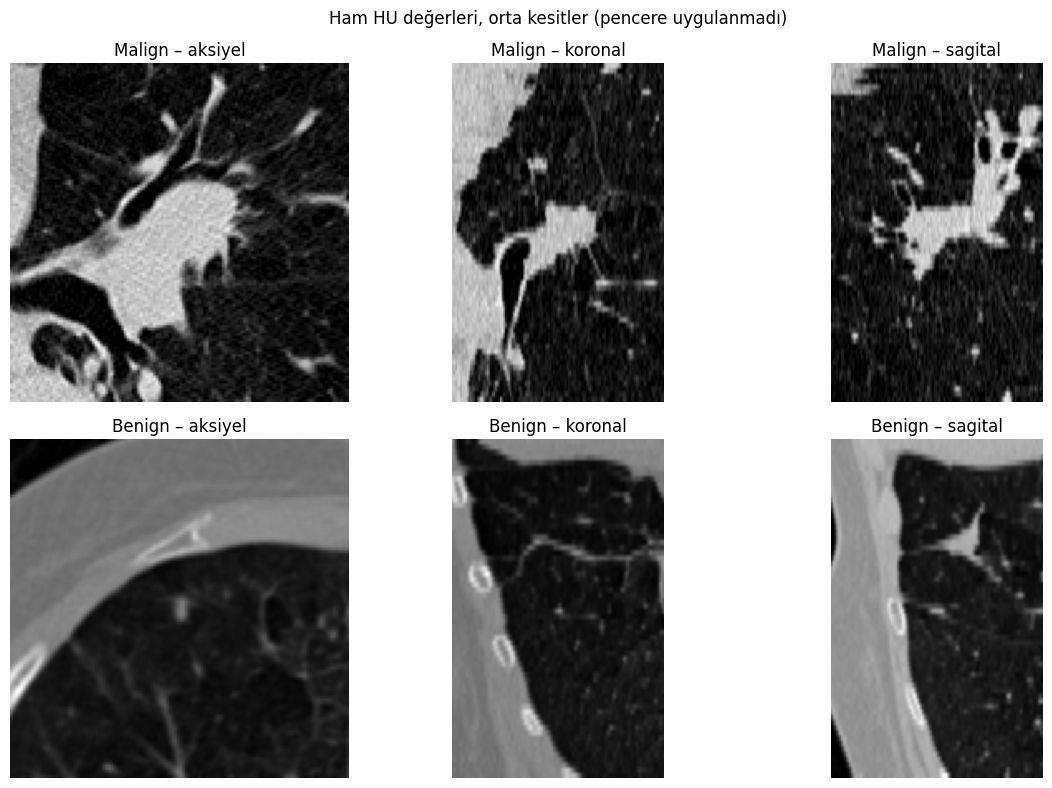

In [9]:
import matplotlib.pyplot as plt
os.makedirs("/content/sunum_gorselleri", exist_ok=True)

malign_id = df.loc[df["label"] == 1, "AnnotationID"].iloc[0]
benign_id = df.loc[df["label"] == 0, "AnnotationID"].iloc[0]
dz, dy, dx = 2.0, 0.625, 0.625   # voksel boyutu (mm)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for satir, (aid, ad) in enumerate([(malign_id, "Malign"), (benign_id, "Benign")]):
    v = np.load(f"{img_dir}/{aid}.npy")
    zc, yc, xc = [s // 2 for s in v.shape]

    axes[satir, 0].imshow(v[zc], cmap="gray", aspect=dy / dx)
    axes[satir, 0].set_title(f"{ad} – aksiyel")
    axes[satir, 1].imshow(v[:, yc, :], cmap="gray", aspect=dz / dx)
    axes[satir, 1].set_title(f"{ad} – koronal")
    axes[satir, 2].imshow(v[:, :, xc], cmap="gray", aspect=dz / dy)
    axes[satir, 2].set_title(f"{ad} – sagital")
    for ax in axes[satir]:
        ax.axis("off")

plt.suptitle("Ham HU değerleri, orta kesitler (pencere uygulanmadı)")
plt.tight_layout()
plt.savefig("/content/sunum_gorselleri/01_ham_kesitler.png", dpi=150)
plt.show()

## Adım 8 — HU pencereleme (kontrast germe)
Akciğer penceresi: merkez −600, genişlik 1500 HU → [−1350, 150] aralığı 0–1'e (sonra 0–255'e) doğrusal ölçeklenir, dışı kırpılır.

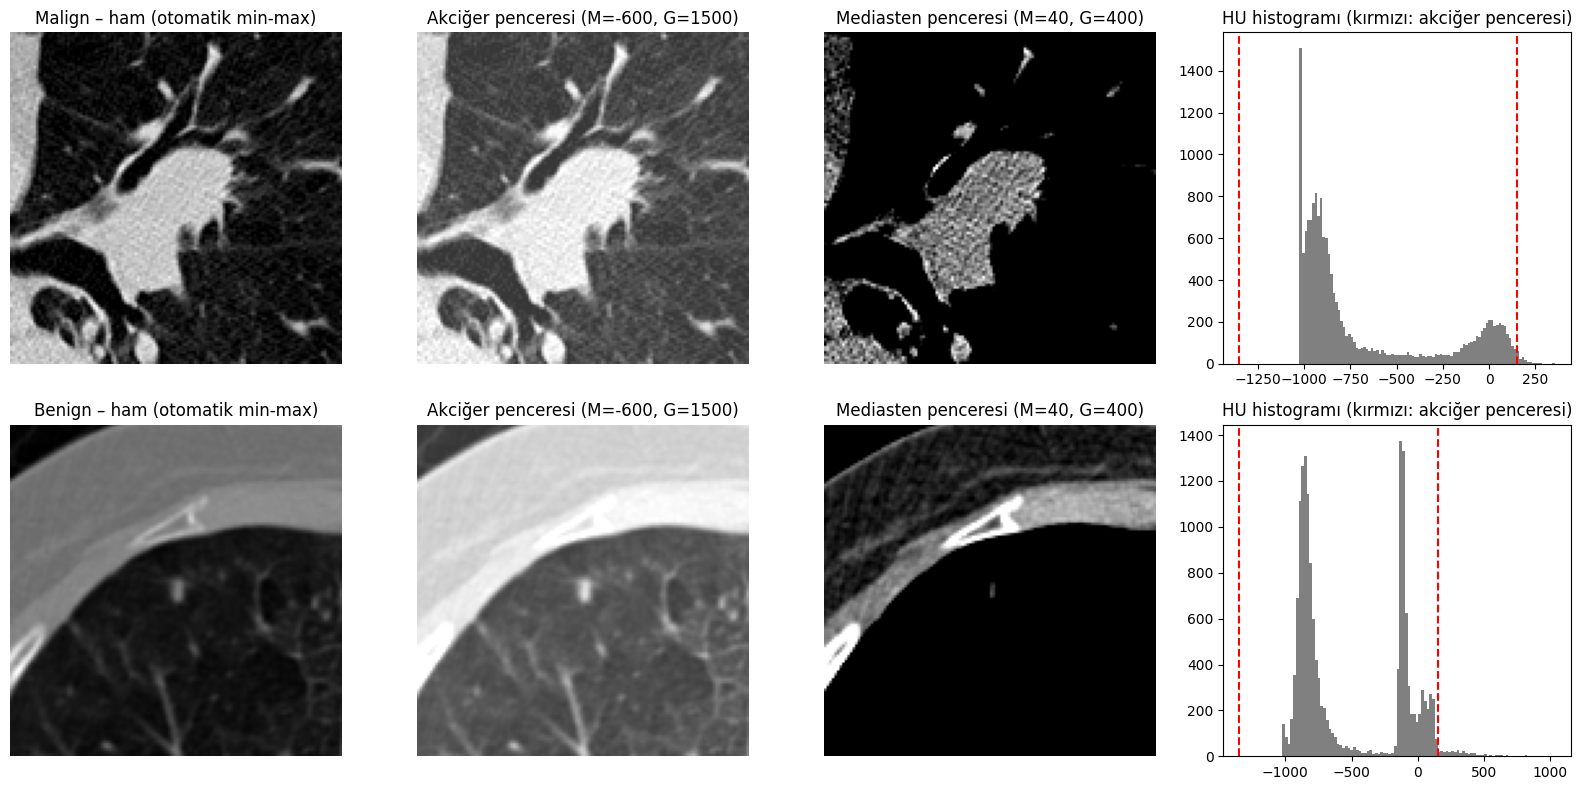

In [10]:
def pencere(v, merkez, genislik):
    alt, ust = merkez - genislik / 2, merkez + genislik / 2
    v = np.clip(v, alt, ust)
    return (v - alt) / (ust - alt)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for satir, (aid, ad) in enumerate([(malign_id, "Malign"), (benign_id, "Benign")]):
    v = np.load(f"{img_dir}/{aid}.npy").astype(np.float32)
    kesit = v[v.shape[0] // 2]

    axes[satir, 0].imshow(kesit, cmap="gray")
    axes[satir, 0].set_title(f"{ad} – ham (otomatik min-max)")
    axes[satir, 1].imshow(pencere(kesit, -600, 1500), cmap="gray", vmin=0, vmax=1)
    axes[satir, 1].set_title("Akciğer penceresi (M=-600, G=1500)")
    axes[satir, 2].imshow(pencere(kesit, 40, 400), cmap="gray", vmin=0, vmax=1)
    axes[satir, 2].set_title("Mediasten penceresi (M=40, G=400)")
    axes[satir, 3].hist(kesit.ravel(), bins=100, color="gray")
    axes[satir, 3].axvline(-1350, color="red", ls="--")
    axes[satir, 3].axvline(150, color="red", ls="--")
    axes[satir, 3].set_title("HU histogramı (kırmızı: akciğer penceresi)")
    for ax in axes[satir, :3]:
        ax.axis("off")

plt.tight_layout()
plt.savefig("/content/sunum_gorselleri/02_pencereleme.png", dpi=150)
plt.show()

## Adım 9 — Histogram eşitleme ve CLAHE

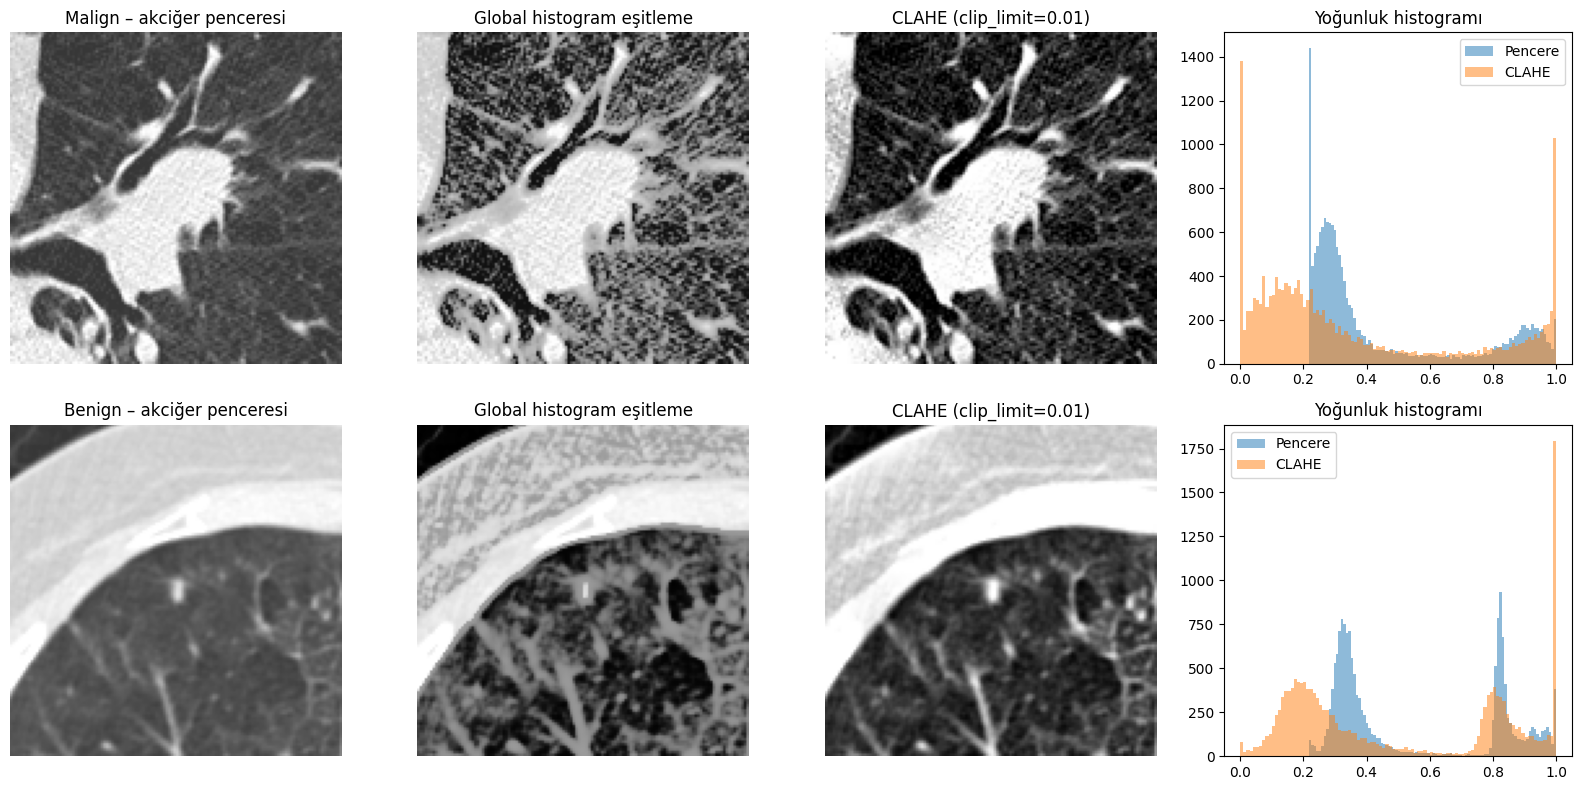

In [11]:
from skimage import exposure

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for satir, (aid, ad) in enumerate([(malign_id, "Malign"), (benign_id, "Benign")]):
    v = np.load(f"{img_dir}/{aid}.npy").astype(np.float32)
    akc = pencere(v[v.shape[0] // 2], -600, 1500)

    global_he = exposure.equalize_hist(akc)
    clahe = exposure.equalize_adapthist(akc, clip_limit=0.01)

    axes[satir, 0].imshow(akc, cmap="gray", vmin=0, vmax=1)
    axes[satir, 0].set_title(f"{ad} – akciğer penceresi")
    axes[satir, 1].imshow(global_he, cmap="gray", vmin=0, vmax=1)
    axes[satir, 1].set_title("Global histogram eşitleme")
    axes[satir, 2].imshow(clahe, cmap="gray", vmin=0, vmax=1)
    axes[satir, 2].set_title("CLAHE (clip_limit=0.01)")
    axes[satir, 3].hist(akc.ravel(), bins=100, alpha=0.5, label="Pencere")
    axes[satir, 3].hist(clahe.ravel(), bins=100, alpha=0.5, label="CLAHE")
    axes[satir, 3].legend()
    axes[satir, 3].set_title("Yoğunluk histogramı")
    for ax in axes[satir, :3]:
        ax.axis("off")

plt.tight_layout()
plt.savefig("/content/sunum_gorselleri/03_kontrast.png", dpi=150)
plt.show()

## Adım 10 — Tüm veriyi işleyip Drive'a kaydetme
2,5B girdi: orta kesit ve ±1 komşu kesit = 3 kanal, uint8. Pencere ve CLAHE dizileri kaydedilir.

In [13]:
from google.colab import drive
from tqdm.auto import tqdm

drive.mount("/content/drive")
cikti = "/content/drive/MyDrive/akciger_nodul_LUNA25"
os.makedirs(cikti, exist_ok=True)

def on_isle(aid):
    v = np.load(f"{img_dir}/{aid}.npy").astype(np.float32)
    assert v.shape == (64, 128, 128), f"{aid}: beklenmeyen boyut {v.shape}"
    zc = v.shape[0] // 2
    pen = np.stack([pencere(v[z], -600, 1500) for z in (zc - 1, zc, zc + 1)])
    cla = np.stack([exposure.equalize_adapthist(k, clip_limit=0.01) for k in pen])
    return pen, cla

N = len(df)
X_pencere = np.zeros((N, 3, 128, 128), dtype=np.uint8)
X_clahe = np.zeros((N, 3, 128, 128), dtype=np.uint8)

for i, aid in enumerate(tqdm(df["AnnotationID"])):
    pen, cla = on_isle(aid)
    X_pencere[i] = (pen * 255).round().astype(np.uint8)
    X_clahe[i] = (cla * 255).round().astype(np.uint8)

np.save(f"{cikti}/X_pencere.npy", X_pencere)
np.save(f"{cikti}/X_clahe.npy", X_clahe)
df.to_csv(f"{cikti}/etiketler_bolunmus.csv", index=False)
!cp -r /content/sunum_gorselleri "{cikti}/"

print("X_pencere:", X_pencere.shape, "| X_clahe:", X_clahe.shape)
!ls -lh "{cikti}"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


  0%|          | 0/6163 [00:00<?, ?it/s]

X_pencere: (6163, 3, 128, 128) | X_clahe: (6163, 3, 128, 128)
total 579M
-rw------- 1 root root 849K Nov 20 23:09 etiketler_bolunmus.csv
drwx------ 2 root root 4.0K Nov 20 23:09 sunum_gorselleri
-rw------- 1 root root 289M Nov 20 23:09 X_clahe.npy
-rw------- 1 root root 289M Nov 20 23:09 X_pencere.npy


## Adım 11 — Kaydedilen dizileri yükleme ve kontrol

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
X_pencere: (6163, 3, 128, 128) | X_clahe: (6163, 3, 128, 128) | df: (6163, 13)


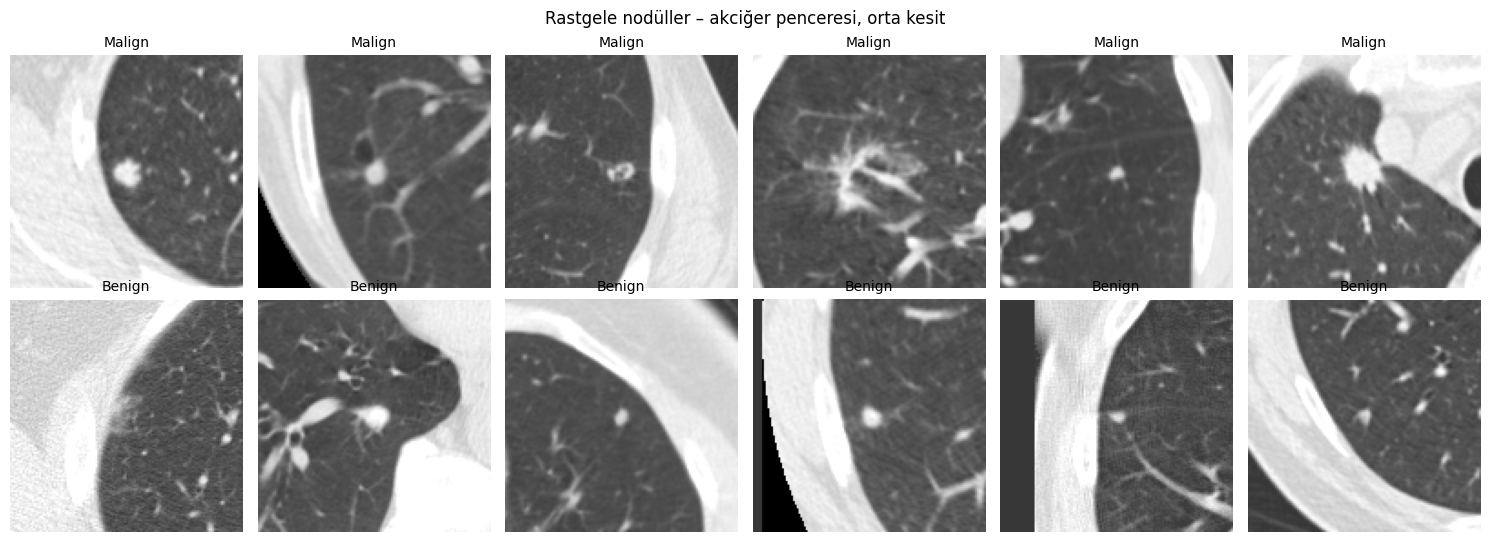

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount("/content/drive")
cikti = "/content/drive/MyDrive/akciger_nodul_LUNA25"

X_pencere = np.load(f"{cikti}/X_pencere.npy")
X_clahe = np.load(f"{cikti}/X_clahe.npy")
df = pd.read_csv(f"{cikti}/etiketler_bolunmus.csv")
print("X_pencere:", X_pencere.shape, "| X_clahe:", X_clahe.shape, "| df:", df.shape)

rng = np.random.default_rng(0)
fig, axes = plt.subplots(2, 6, figsize=(15, 5.5))
for satir, (etiket, ad) in enumerate([(1, "Malign"), (0, "Benign")]):
    idx = rng.choice(np.where(df["label"] == etiket)[0], 6, replace=False)
    for j, i in enumerate(idx):
        axes[satir, j].imshow(X_pencere[i, 1], cmap="gray", vmin=0, vmax=255)
        axes[satir, j].set_title(ad, fontsize=10)
        axes[satir, j].axis("off")

plt.suptitle("Rastgele nodüller – akciğer penceresi, orta kesit")
plt.tight_layout()
plt.savefig(f"{cikti}/sunum_gorselleri/04_ornek_noduller.png", dpi=150)
plt.show()

## Adım 12 — Oturum yenilendikten sonra tanımlar + veri tutarlılık kontrolleri (nodül/hasta sayıları)

In [15]:
import os

def pencere(v, merkez, genislik):
    alt, ust = merkez - genislik / 2, merkez + genislik / 2
    return (np.clip(v, alt, ust) - alt) / (ust - alt)

# 1) Tekrarlanan nodüller
tekrar = df.groupby("NoduleID").agg(
    goruntu_sayisi=("AnnotationID", "count"),
    etiket_sayisi=("label", "nunique"))
print("Farklı etiket taşıyan nodül:", (tekrar["etiket_sayisi"] > 1).sum())
print("\nNodül başına görüntü sayısı:")
print(tekrar["goruntu_sayisi"].value_counts().sort_index())
for etiket, ad in [(1, "Malign"), (0, "Benign")]:
    alt = df[df["label"] == etiket]
    print(f"{ad}: {len(alt)} kayıt | {alt['NoduleID'].nunique()} benzersiz nodül | {alt['PatientID'].nunique()} hasta")

# 2) Görüntü-etiket eşleşmesi: 20 rastgele satırı ham bloklardan yeniden hesapla
img_dir = "/content/luna25/bloklar/luna25_nodule_blocks/image"
if os.path.exists(img_dir):
    rng = np.random.default_rng(1)
    for i in rng.choice(len(df), 20, replace=False):
        v = np.load(f"{img_dir}/{df['AnnotationID'][i]}.npy").astype(np.float32)
        zc = v.shape[0] // 2
        beklenen = (np.stack([pencere(v[z], -600, 1500) for z in (zc - 1, zc, zc + 1)]) * 255).round().astype(np.uint8)
        assert np.array_equal(beklenen, X_pencere[i]), f"Eşleşme hatası: satır {i}"
    print("\n20 rastgele örnekte görüntü-etiket eşleşmesi doğrulandı.")
else:
    print("\nHam bloklar bu oturumda yok, eşleşme kontrolü atlandı.")

np.save(f"{cikti}/annotation_ids.npy", df["AnnotationID"].values.astype(str))
print("AnnotationID sırası Drive'a kaydedildi.")

Farklı etiket taşıyan nodül: 0

Nodül başına görüntü sayısı:
goruntu_sayisi
1    2159
2     805
3     798
Name: count, dtype: int64
Malign: 555 kayıt | 348 benzersiz nodül | 333 hasta
Benign: 5608 kayıt | 3414 benzersiz nodül | 1787 hasta

20 rastgele örnekte görüntü-etiket eşleşmesi doğrulandı.
AnnotationID sırası Drive'a kaydedildi.


## Adım 13 — Gürültü filtreleme: Gauss, medyan, bilateral (orijinal − filtreli farkı)

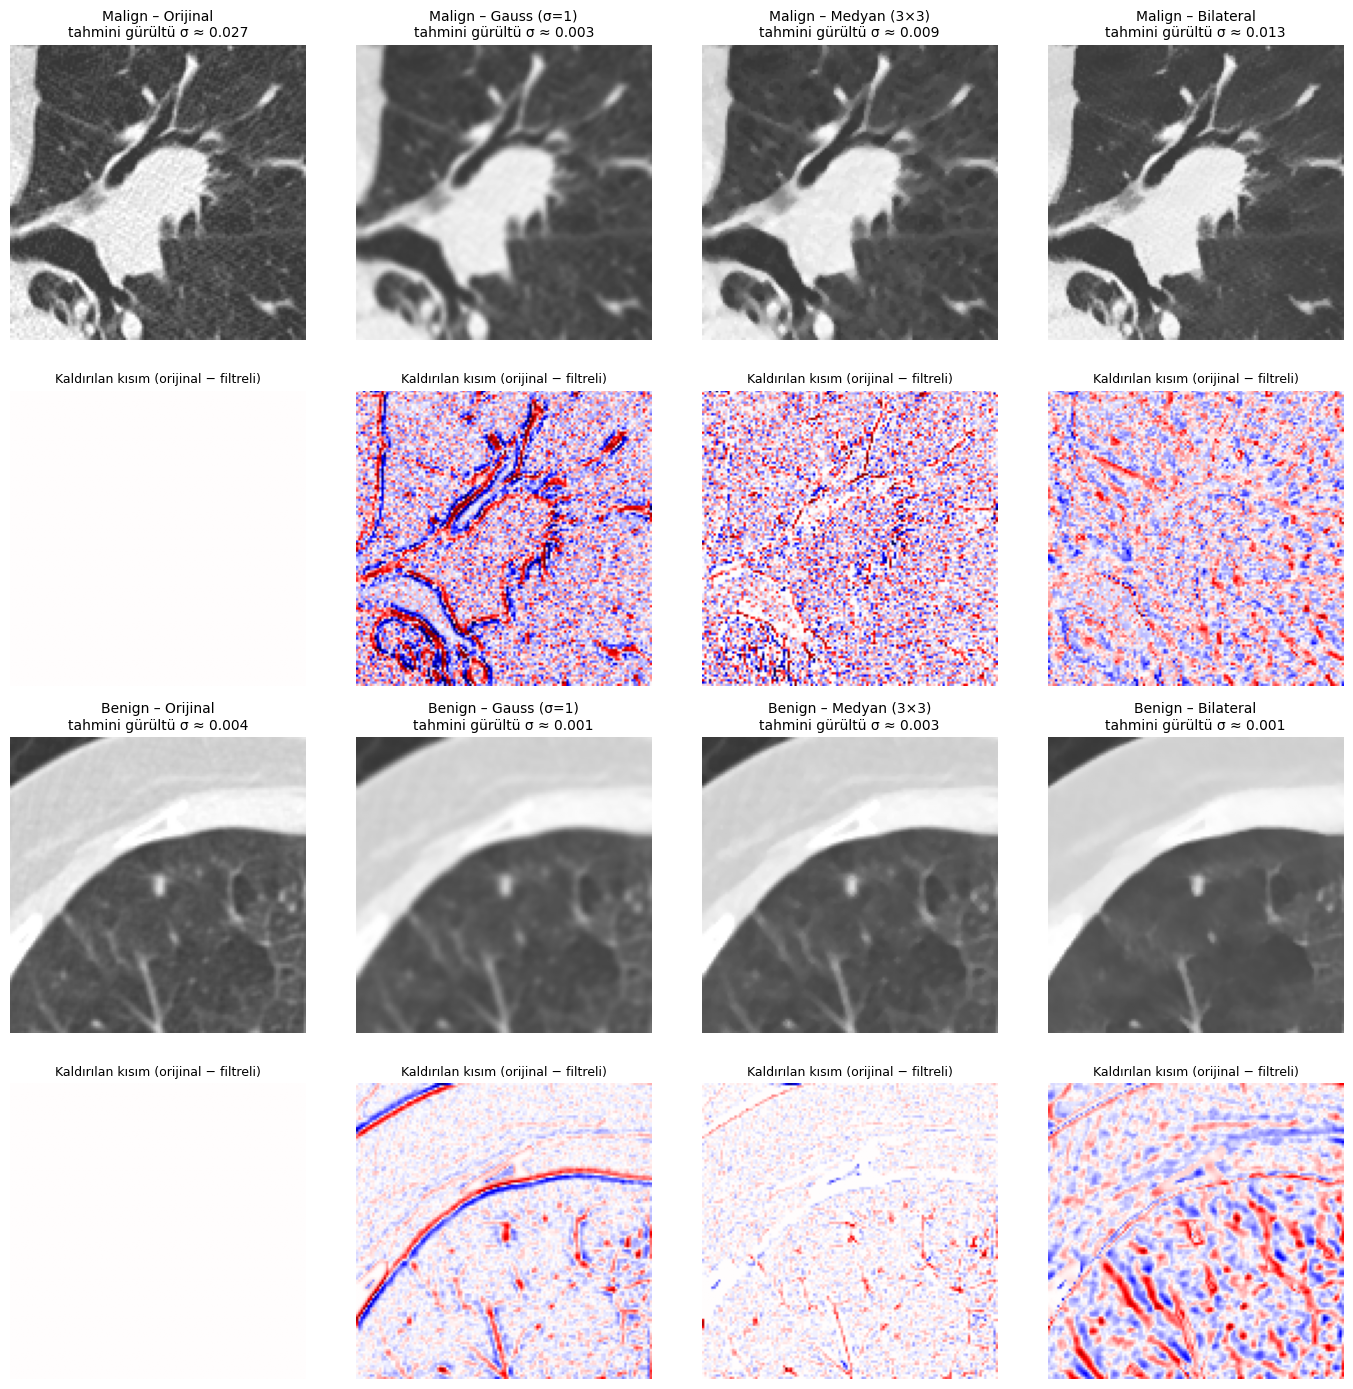

In [16]:
from scipy import ndimage
from skimage.restoration import denoise_bilateral, estimate_sigma

i_m = np.where(df["label"] == 1)[0][0]   # Adım 7'deki malign örnek
i_b = np.where(df["label"] == 0)[0][0]   # Adım 7'deki benign örnek

filtreler = {
    "Orijinal": lambda k: k,
    "Gauss (σ=1)": lambda k: ndimage.gaussian_filter(k, sigma=1),
    "Medyan (3×3)": lambda k: ndimage.median_filter(k, size=3),
    "Bilateral": lambda k: denoise_bilateral(k, sigma_color=0.05, sigma_spatial=1.5),
}

fig, axes = plt.subplots(4, 4, figsize=(14, 14))
for blok, (i, ad) in enumerate([(i_m, "Malign"), (i_b, "Benign")]):
    k = X_pencere[i, 1].astype(np.float32) / 255
    for j, (fad, f) in enumerate(filtreler.items()):
        s = f(k)
        ust, alt = axes[2 * blok, j], axes[2 * blok + 1, j]
        ust.imshow(s, cmap="gray", vmin=0, vmax=1)
        ust.set_title(f"{ad} – {fad}\ntahmini gürültü σ ≈ {estimate_sigma(s):.3f}", fontsize=10)
        alt.imshow(k - s, cmap="seismic", vmin=-0.15, vmax=0.15)
        alt.set_title("Kaldırılan kısım (orijinal − filtreli)", fontsize=9)
        ust.axis("off")
        alt.axis("off")

plt.tight_layout()
plt.savefig(f"{cikti}/sunum_gorselleri/05_gurultu_filtreleme.png", dpi=150)
plt.show()

## Adım 14 — Medyan filtreyi tüm veriye uygulama

X_medyan: (6163, 3, 128, 128) uint8


  0%|          | 0/6163 [00:00<?, ?it/s]

        count    mean     std     min     25%     50%     75%     max
label                                                                
0      5608.0  0.0119  0.0130  0.0010  0.0046  0.0069  0.0130  0.1456
1       555.0  0.0129  0.0145  0.0023  0.0049  0.0068  0.0138  0.0941
Gürültü düzeyinin etiketi tahmin gücü (ROC-AUC): 0.516


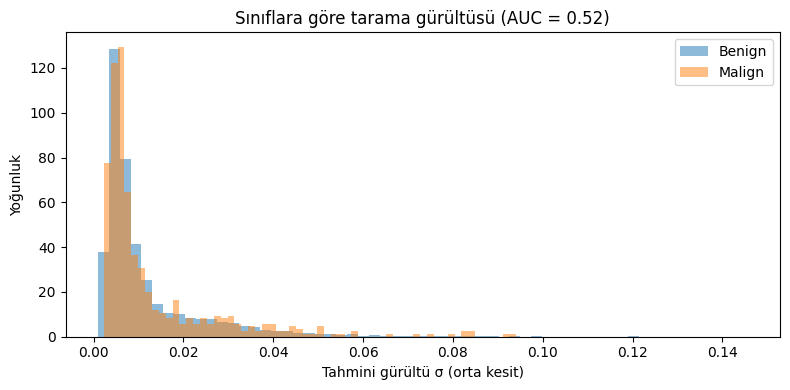

In [17]:
from tqdm.auto import tqdm
from sklearn.metrics import roc_auc_score

# 1) Bütün veriye medyan filtre (her kanala ayrı ayrı, 3×3)
X_medyan = ndimage.median_filter(X_pencere, size=(1, 1, 3, 3))
np.save(f"{cikti}/X_medyan.npy", X_medyan)
print("X_medyan:", X_medyan.shape, X_medyan.dtype)

# 2) Her taramanın gürültü düzeyi
df["gurultu"] = [estimate_sigma(X_pencere[i, 1].astype(np.float32) / 255)
                 for i in tqdm(range(len(df)))]
print(df.groupby("label")["gurultu"].describe().round(4))
auc = roc_auc_score(df["label"], df["gurultu"])
print("Gürültü düzeyinin etiketi tahmin gücü (ROC-AUC):", round(auc, 3))

fig, ax = plt.subplots(figsize=(8, 4))
for etiket, ad in [(0, "Benign"), (1, "Malign")]:
    ax.hist(df.loc[df["label"] == etiket, "gurultu"], bins=60, alpha=0.5, density=True, label=ad)
ax.set_xlabel("Tahmini gürültü σ (orta kesit)")
ax.set_ylabel("Yoğunluk")
ax.set_title(f"Sınıflara göre tarama gürültüsü (AUC = {auc:.2f})")
ax.legend()
plt.tight_layout()
plt.savefig(f"{cikti}/sunum_gorselleri/06_gurultu_dagilimi.png", dpi=150)
plt.show()

## Adım 15 — Klasik bölütleme (v1): Otsu eşikleme + morfoloji + bağlantılı bileşen

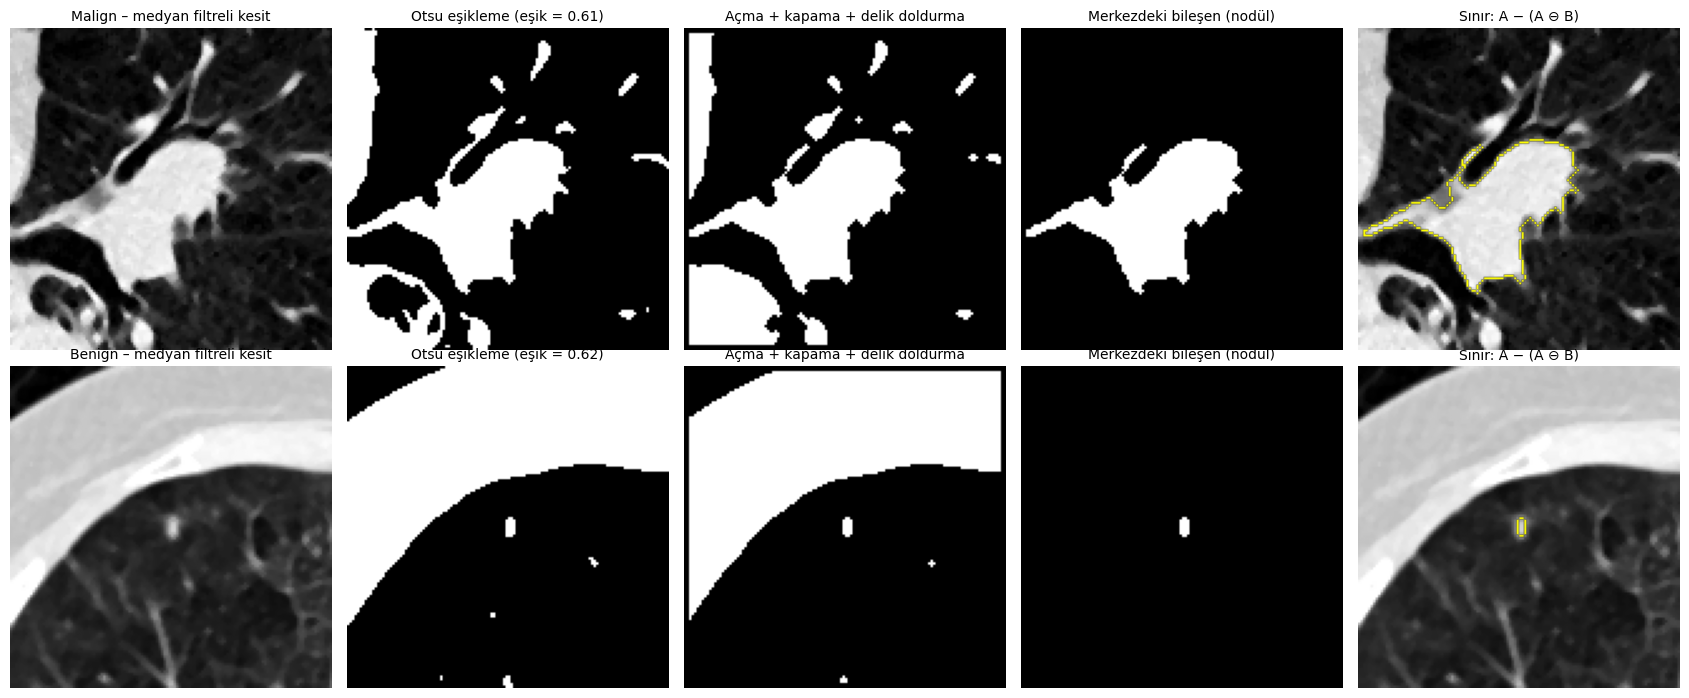

In [18]:
from skimage.filters import threshold_otsu
from skimage.measure import label, regionprops
from skimage.morphology import disk

def bolutle(k, ara_adimlar=False):
    m = 32
    esik = threshold_otsu(k[64 - m:64 + m, 64 - m:64 + m])
    maske = k > esik
    acik = ndimage.binary_opening(maske, structure=disk(1))
    kapali = ndimage.binary_fill_holes(ndimage.binary_closing(acik, structure=disk(2)))

    etiketler = label(kapali)
    if etiketler[64, 64] > 0:
        nodul = etiketler == etiketler[64, 64]
    elif etiketler.max() > 0:
        en_yakin = min(regionprops(etiketler),
                       key=lambda r: np.hypot(r.centroid[0] - 64, r.centroid[1] - 64))
        nodul = etiketler == en_yakin.label
    else:
        nodul = np.zeros_like(kapali)

    if ara_adimlar:
        return esik, maske, kapali, nodul
    return nodul

def morf_sinir(A):
    return A & ~ndimage.binary_erosion(A, structure=disk(1))   # β(A) = A − (A ⊖ B)

fig, axes = plt.subplots(2, 5, figsize=(17, 7))
for satir, (i, ad) in enumerate([(i_m, "Malign"), (i_b, "Benign")]):
    k = X_medyan[i, 1].astype(np.float32) / 255
    esik, maske, kapali, nodul = bolutle(k, ara_adimlar=True)
    sinir = morf_sinir(nodul)
    gorseller = [
        (k, f"{ad} – medyan filtreli kesit"),
        (maske, f"Otsu eşikleme (eşik = {esik:.2f})"),
        (kapali, "Açma + kapama + delik doldurma"),
        (nodul, "Merkezdeki bileşen (nodül)"),
    ]
    for j, (g, baslik) in enumerate(gorseller):
        axes[satir, j].imshow(g, cmap="gray")
        axes[satir, j].set_title(baslik, fontsize=10)
    axes[satir, 4].imshow(k, cmap="gray")
    axes[satir, 4].imshow(np.ma.masked_where(~sinir, sinir), cmap="autumn", vmin=0, vmax=1)
    axes[satir, 4].set_title("Sınır: A − (A ⊖ B)", fontsize=10)
    for ax in axes[satir]:
        ax.axis("off")

plt.tight_layout()
plt.savefig(f"{cikti}/sunum_gorselleri/07_bolutleme_adimlari.png", dpi=150)
plt.show()

## Adım 16 — Kenar dolgusu düzeltmesi
Sıfır dolgu görüntü kenarında sahte yapı üretiyordu; `np.pad(mode="edge")` (MATLAB: `padarray(..., 'replicate')`) ile düzeltildi.

  0%|          | 0/6163 [00:00<?, ?it/s]

Boş maske: 0
Merkez pikseli nodülde değil: 286
Görüntü kenarına değen maske (duvar/damarla birleşmiş olabilir): 2463
      alan (piksel)                                                    
              count    mean     std  min    25%    50%     75%      max
label                                                                  
0            5608.0  3467.8  4518.1  5.0   40.0  137.5  7626.2  16384.0
1             555.0  3183.6  3924.7  5.0  145.0  462.0  7433.0  16329.0


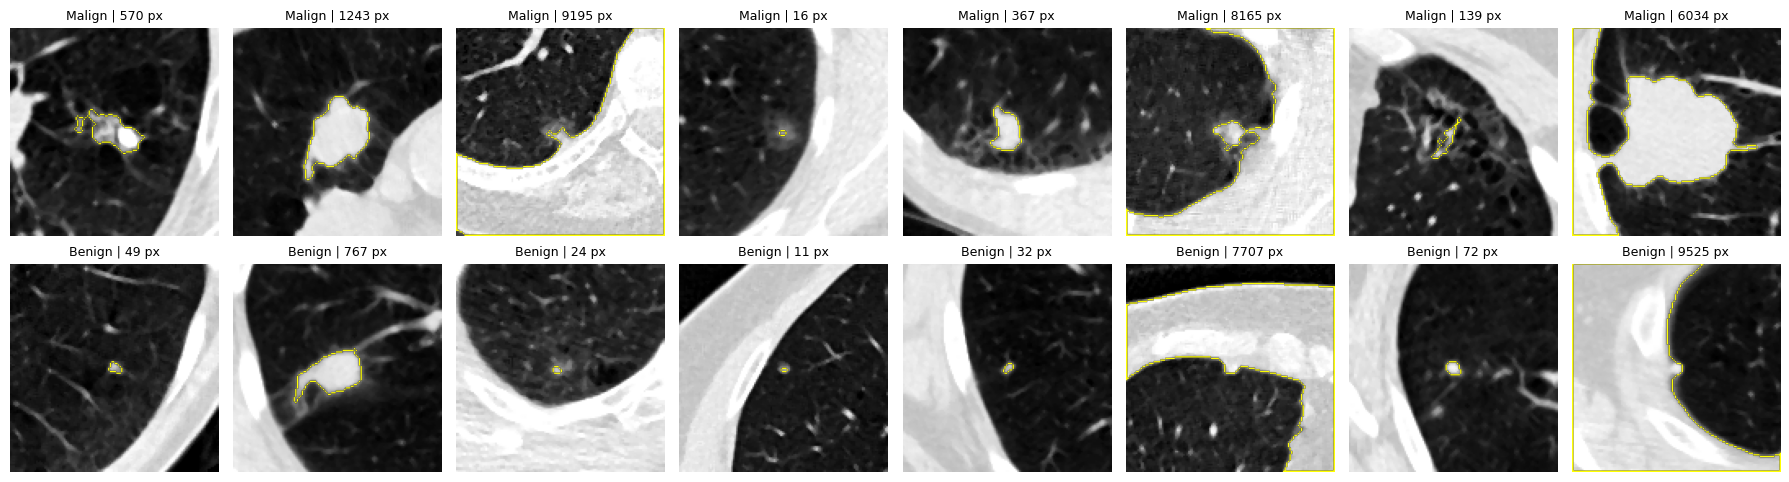

In [19]:
def morf(A, islem, r):
    p = r + 1
    A = np.pad(A, p, mode="edge")          # 'replicate' dolgu
    return islem(A, structure=disk(r))[p:-p, p:-p]

def bolutle(k):
    esik = threshold_otsu(k[32:96, 32:96])
    acik = morf(k > esik, ndimage.binary_opening, 1)
    kapali = ndimage.binary_fill_holes(morf(acik, ndimage.binary_closing, 2))
    etiketler = label(kapali)
    if etiketler[64, 64] > 0:
        return etiketler == etiketler[64, 64], True
    if etiketler.max() > 0:
        en_yakin = min(regionprops(etiketler),
                       key=lambda r: np.hypot(r.centroid[0] - 64, r.centroid[1] - 64))
        return etiketler == en_yakin.label, False
    return np.zeros_like(kapali), False

N = len(df)
maskeler = np.zeros((N, 128, 128), dtype=bool)
merkezde = np.zeros(N, dtype=bool)
for i in tqdm(range(N)):
    maskeler[i], merkezde[i] = bolutle(X_medyan[i, 1].astype(np.float32) / 255)

alan = maskeler.sum(axis=(1, 2))
kenara_degen = maskeler[:, [0, -1], :].any(axis=(1, 2)) | maskeler[:, :, [0, -1]].any(axis=(1, 2))
print("Boş maske:", (alan == 0).sum())
print("Merkez pikseli nodülde değil:", (~merkezde).sum())
print("Görüntü kenarına değen maske (duvar/damarla birleşmiş olabilir):", kenara_degen.sum())
print(pd.DataFrame({"alan (piksel)": alan, "label": df["label"]}).groupby("label").describe().round(1))

np.savez_compressed(f"{cikti}/maskeler.npz", maskeler=maskeler, merkezde=merkezde)

rng = np.random.default_rng(2)
fig, axes = plt.subplots(2, 8, figsize=(18, 5))
for satir, (etiket, ad) in enumerate([(1, "Malign"), (0, "Benign")]):
    for j, i in enumerate(rng.choice(np.where(df["label"] == etiket)[0], 8, replace=False)):
        axes[satir, j].imshow(X_medyan[i, 1], cmap="gray")
        sinir = maskeler[i] & ~ndimage.binary_erosion(maskeler[i], structure=disk(1))
        axes[satir, j].imshow(np.ma.masked_where(~sinir, sinir), cmap="autumn", vmin=0, vmax=1)
        axes[satir, j].set_title(f"{ad} | {alan[i]} px", fontsize=9)
        axes[satir, j].axis("off")
plt.tight_layout()
plt.savefig(f"{cikti}/sunum_gorselleri/08_bolutleme_ornekleri.png", dpi=150)
plt.show()

## Adım 17 — Watershed ile duvardan ayırma (uzaklık dönüşümü + işaretleyici)

  0%|          | 0/6163 [00:00<?, ?it/s]

Boş maske: 0
Merkez pikseli maskede değil: 286
Görüntü kenarına değen maske: 0
      alan (piksel)                                               
              count   mean    std  min   25%    50%    75%     max
label                                                             
0            5608.0   87.6  252.0  1.0  14.0   36.0   75.0  8950.0
1             555.0  357.2  743.6  1.0  53.5  155.0  376.5  9894.0


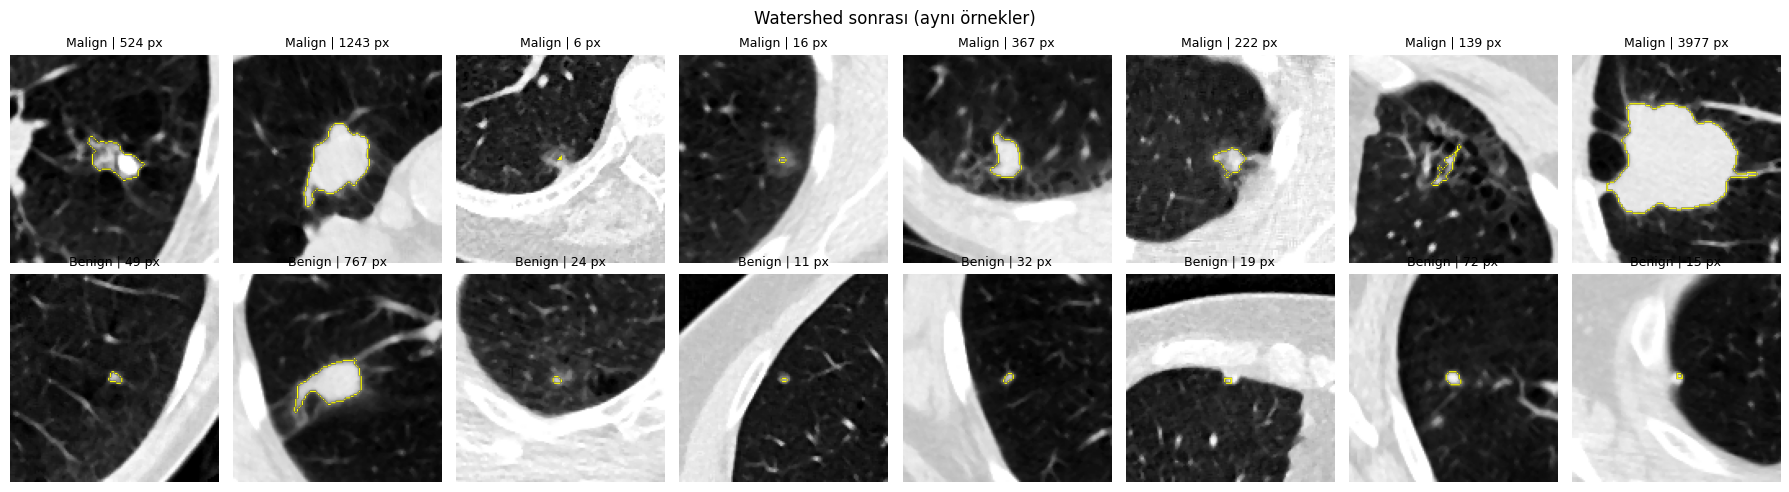

In [20]:
from skimage.segmentation import watershed

KENAR = np.zeros((128, 128), dtype=bool)
KENAR[[0, -1], :] = True
KENAR[:, [0, -1]] = True
yy, xx = np.mgrid[:128, :128]
MERKEZE_UZAKLIK = np.hypot(yy - 64, xx - 64)

def bolutle_ws(k):
    esik = threshold_otsu(k[32:96, 32:96])
    acik = morf(k > esik, ndimage.binary_opening, 1)
    kapali = ndimage.binary_fill_holes(morf(acik, ndimage.binary_closing, 2))
    if not kapali.any():
        return kapali, False

    uz = np.where(kapali, MERKEZE_UZAKLIK, np.inf)
    ty, tx = np.unravel_index(np.argmin(uz), uz.shape)

    isaret = np.zeros((128, 128), dtype=int)
    isaret[KENAR & kapali] = 2      # duvar / kenara uzanan yapılar
    isaret[ty, tx] = 1              # nodül tohumu
    dist = ndimage.distance_transform_edt(kapali)
    ws = watershed(-dist, isaret, mask=kapali)
    return ws == 1, bool(kapali[64, 64])

maskeler = np.zeros((N, 128, 128), dtype=bool)
merkezde = np.zeros(N, dtype=bool)
for i in tqdm(range(N)):
    maskeler[i], merkezde[i] = bolutle_ws(X_medyan[i, 1].astype(np.float32) / 255)

alan = maskeler.sum(axis=(1, 2))
kenara_degen = maskeler[:, [0, -1], :].any(axis=(1, 2)) | maskeler[:, :, [0, -1]].any(axis=(1, 2))
print("Boş maske:", (alan == 0).sum())
print("Merkez pikseli maskede değil:", (~merkezde).sum())
print("Görüntü kenarına değen maske:", kenara_degen.sum())
print(pd.DataFrame({"alan (piksel)": alan, "label": df["label"]}).groupby("label").describe().round(1))

np.savez_compressed(f"{cikti}/maskeler.npz", maskeler=maskeler, merkezde=merkezde)

rng = np.random.default_rng(2)
fig, axes = plt.subplots(2, 8, figsize=(18, 5))
for satir, (etiket, ad) in enumerate([(1, "Malign"), (0, "Benign")]):
    for j, i in enumerate(rng.choice(np.where(df["label"] == etiket)[0], 8, replace=False)):
        axes[satir, j].imshow(X_medyan[i, 1], cmap="gray")
        sinir = maskeler[i] & ~ndimage.binary_erosion(maskeler[i], structure=disk(1))
        axes[satir, j].imshow(np.ma.masked_where(~sinir, sinir), cmap="autumn", vmin=0, vmax=1)
        axes[satir, j].set_title(f"{ad} | {alan[i]} px", fontsize=9)
        axes[satir, j].axis("off")
plt.suptitle("Watershed sonrası (aynı örnekler)")
plt.tight_layout()
plt.savefig(f"{cikti}/sunum_gorselleri/09_watershed_ornekleri.png", dpi=150)
plt.show()

## Adım 18 — Özellik çıkarma ve klasik sınıflandırıcılar (v1 özellikleri)

In [22]:
from skimage.measure import regionprops
from skimage.filters import sobel
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

def ozellikler(i):
    m = maskeler[i]
    k = X_medyan[i, 1].astype(np.float32)
    hu = k / 255 * 1500 - 1350                      # pencereyi geri çevir → HU
    r = regionprops(m.astype(int))[0]
    cevre_px = max(r.perimeter, 1)
    sinir = m & ~ndimage.binary_erosion(m, structure=disk(1))
    return {
        "alan_mm2": r.area * 0.625 ** 2,
        "esdeger_cap_mm": r.equivalent_diameter_area * 0.625,
        "dairesellik": 4 * np.pi * r.area / cevre_px ** 2,
        "doluluk": r.solidity,
        "eksantriklik": r.eccentricity,
        "ort_hu": hu[m].mean(),
        "std_hu": hu[m].std(),
        "kalsifikasyon_orani": (k[m] >= 254).mean(),
        "kenar_gradyani": sobel(k / 255)[sinir].mean(),
    }

F = pd.DataFrame([ozellikler(i) for i in tqdm(range(N))])
F.to_csv(f"{cikti}/ozellikler.csv", index=False)
print("Sınıflara göre medyan değerler:")
print(F.groupby(df["label"].values).median().T.round(3))

y = df["label"].values
fold = df["fold"].values
modeller = {
    "Sadece alan (lojistik regresyon)": (lambda: LogisticRegression(class_weight="balanced"), ["alan_mm2"]),
    "Tüm özellikler (Random Forest)": (lambda: RandomForestClassifier(
        n_estimators=300, min_samples_leaf=5, class_weight="balanced", random_state=42, n_jobs=-1),
        list(F.columns)),
}
onem = np.zeros(F.shape[1])
for ad, (yap, sutunlar) in modeller.items():
    auc, pr = [], []
    for k in range(5):
        eg = (fold != k) & (fold != -1)
        dg = fold == k
        Xe, Xd = F.loc[eg, sutunlar], F.loc[dg, sutunlar]
        if ad.startswith("Sadece"):
            Xe, Xd = np.log1p(Xe), np.log1p(Xd)
        model = yap().fit(Xe, y[eg])
        p = model.predict_proba(Xd)[:, 1]
        auc.append(roc_auc_score(y[dg], p))
        pr.append(average_precision_score(y[dg], p))
        if ad.startswith("Tüm"):
            onem += model.feature_importances_ / 5
    print(f"{ad}: ROC-AUC = {np.mean(auc):.3f} ± {np.std(auc):.3f} | PR-AUC = {np.mean(pr):.3f} ± {np.std(pr):.3f}")

print("\nRastgele tahminin PR-AUC'si (malign oranı):", round(y[fold != -1].mean(), 3))
print("\nRandom Forest özellik önemleri:")
print(pd.Series(onem, index=F.columns).sort_values(ascending=False).round(3))


  0%|          | 0/6163 [00:00<?, ?it/s]

Sınıflara göre medyan değerler:
                           0        1
alan_mm2              14.062   60.547
esdeger_cap_mm         4.231    8.780
dairesellik            1.104    0.764
doluluk                0.965    0.899
eksantriklik           0.723    0.763
ort_hu              -214.706 -176.675
std_hu               120.710  144.749
kalsifikasyon_orani    0.000    0.000
kenar_gradyani         0.166    0.162
Sadece alan (lojistik regresyon): ROC-AUC = 0.744 ± 0.022 | PR-AUC = 0.292 ± 0.034
Tüm özellikler (Random Forest): ROC-AUC = 0.789 ± 0.027 | PR-AUC = 0.312 ± 0.041

Rastgele tahminin PR-AUC'si (malign oranı): 0.089

Random Forest özellik önemleri:
esdeger_cap_mm         0.179
alan_mm2               0.172
dairesellik            0.131
kenar_gradyani         0.125
ort_hu                 0.116
std_hu                 0.095
eksantriklik           0.092
doluluk                0.077
kalsifikasyon_orani    0.013
dtype: float64


## Adım 19 — CNN (ResNet-18, ImageNet ön eğitimli) ilk deneme

In [23]:
import time
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms.v2 as T
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

cihaz = "cuda" if torch.cuda.is_available() else "cpu"
print("Cihaz:", cihaz)

ORT, SS = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
egitim_donusum = T.Compose([
    T.RandomHorizontalFlip(), T.RandomVerticalFlip(),
    T.RandomApply([T.RandomRotation((90, 90))], p=0.5),
    T.Resize(224, antialias=True), T.Normalize(ORT, SS)])
deg_donusum = T.Compose([T.Resize(224, antialias=True), T.Normalize(ORT, SS)])

class NodulVeriSeti(Dataset):
    def __init__(self, X, y, donusum):
        self.X, self.y, self.donusum = X, y, donusum
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        x = torch.from_numpy(self.X[i]).float() / 255.0
        return self.donusum(x), torch.tensor(self.y[i], dtype=torch.float32)

goruntu_say = df.groupby("NoduleID")["AnnotationID"].transform("count").values

def yukleyiciler(X, k, batch=64):
    eg = np.where((fold != k) & (fold != -1))[0]
    dg = np.where(fold == k)[0]
    nodul_say = df.iloc[eg].groupby("label")["NoduleID"].nunique()
    w = 1.0 / (nodul_say.loc[y[eg]].values * goruntu_say[eg])
    ornekleyici = WeightedRandomSampler(torch.as_tensor(w, dtype=torch.double),
                                        num_samples=len(eg), replacement=True)
    egl = DataLoader(NodulVeriSeti(X[eg], y[eg], egitim_donusum), batch_size=batch,
                     sampler=ornekleyici, num_workers=2, pin_memory=True)
    dgl = DataLoader(NodulVeriSeti(X[dg], y[dg], deg_donusum), batch_size=128,
                     shuffle=False, num_workers=2, pin_memory=True)
    return egl, dgl

def model_kur():
    m = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
    m.fc = nn.Linear(m.fc.in_features, 1)
    return m.to(cihaz)

@torch.no_grad()
def tahmin(model, yukleyici):
    model.eval()
    P, Y = [], []
    for x, yb in yukleyici:
        with torch.autocast("cuda"):
            P.append(torch.sigmoid(model(x.to(cihaz))).float().cpu())
        Y.append(yb)
    return torch.cat(P).squeeze(1).numpy(), torch.cat(Y).numpy()

def egit(X, k, epoch=12, lr=3e-4):
    torch.manual_seed(42)
    egl, dgl = yukleyiciler(X, k)
    model = model_kur()
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    zamanlayici = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epoch)
    kayip_f = nn.BCEWithLogitsLoss()
    olcek = torch.amp.GradScaler()
    en_iyi = (-1.0, None, None)
    for e in range(epoch):
        t0 = time.time()
        model.train()
        toplam = 0.0
        for x, yb in egl:
            x, yb = x.to(cihaz), yb.to(cihaz)
            opt.zero_grad()
            with torch.autocast("cuda"):
                kayip = kayip_f(model(x).squeeze(1), yb)
            olcek.scale(kayip).backward()
            olcek.step(opt)
            olcek.update()
            toplam += kayip.item() * len(yb)
        zamanlayici.step()
        p, yd = tahmin(model, dgl)
        auc = roc_auc_score(yd, p)
        print(f"Kat {k} | epoch {e + 1:2d} | eğitim kaybı {toplam / len(egl.dataset):.3f} "
              f"| doğrulama AUC {auc:.3f} | {time.time() - t0:.0f} sn")
        if auc > en_iyi[0]:
            en_iyi = (auc, {a: b.detach().cpu().clone() for a, b in model.state_dict().items()}, p)
    return en_iyi

# ImageNet ağırlıkları gerçekten yüklendi mi?
onceden = model_kur()
rastgele = torchvision.models.resnet18(weights=None)
print("conv1 ağırlık std — ImageNet:", round(onceden.conv1.weight.std().item(), 4),
      "| rastgele başlatma:", round(rastgele.conv1.weight.std().item(), 4))
del onceden, rastgele

auc0, durum0, p0 = egit(X_pencere, k=0)
print("\nKat 0, akciğer penceresi — en iyi doğrulama AUC:", round(auc0, 3))

Cihaz: cuda
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 190MB/s]


conv1 ağırlık std — ImageNet: 0.1297 | rastgele başlatma: 0.0253
Kat 0 | epoch  1 | eğitim kaybı 0.432 | doğrulama AUC 0.850 | 17 sn
Kat 0 | epoch  2 | eğitim kaybı 0.332 | doğrulama AUC 0.881 | 15 sn
Kat 0 | epoch  3 | eğitim kaybı 0.256 | doğrulama AUC 0.871 | 13 sn
Kat 0 | epoch  4 | eğitim kaybı 0.203 | doğrulama AUC 0.845 | 14 sn
Kat 0 | epoch  5 | eğitim kaybı 0.148 | doğrulama AUC 0.878 | 13 sn
Kat 0 | epoch  6 | eğitim kaybı 0.125 | doğrulama AUC 0.864 | 13 sn
Kat 0 | epoch  7 | eğitim kaybı 0.073 | doğrulama AUC 0.876 | 14 sn
Kat 0 | epoch  8 | eğitim kaybı 0.050 | doğrulama AUC 0.879 | 22 sn
Kat 0 | epoch  9 | eğitim kaybı 0.041 | doğrulama AUC 0.874 | 14 sn
Kat 0 | epoch 10 | eğitim kaybı 0.032 | doğrulama AUC 0.887 | 14 sn
Kat 0 | epoch 11 | eğitim kaybı 0.018 | doğrulama AUC 0.885 | 14 sn
Kat 0 | epoch 12 | eğitim kaybı 0.027 | doğrulama AUC 0.882 | 15 sn

Kat 0, akciğer penceresi — en iyi doğrulama AUC: 0.887


## Adım 20 — CNN eğitim fonksiyonları (nodül düzeyinde ağırlıklı örnekleme, AdamW, kosinüs, AMP)

In [1]:
import os, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torchvision
import torchvision.transforms.v2 as T
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from google.colab import drive
from sklearn.metrics import roc_auc_score, average_precision_score

drive.mount("/content/drive")
cikti = "/content/drive/MyDrive/akciger_nodul_LUNA25"

X_pencere = np.load(f"{cikti}/X_pencere.npy")
X_clahe = np.load(f"{cikti}/X_clahe.npy")
X_medyan = np.load(f"{cikti}/X_medyan.npy")
df = pd.read_csv(f"{cikti}/etiketler_bolunmus.csv")
y, fold, N = df["label"].values, df["fold"].values, len(df)
assert (np.load(f"{cikti}/annotation_ids.npy") == df["AnnotationID"].values).all()

cihaz = "cuda" if torch.cuda.is_available() else "cpu"
print("Cihaz:", cihaz, "| Veri:", X_pencere.shape, X_medyan.shape, X_clahe.shape)

ORT, SS = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
egitim_donusum = T.Compose([
    T.RandomHorizontalFlip(), T.RandomVerticalFlip(),
    T.RandomApply([T.RandomRotation((90, 90))], p=0.5),
    T.Resize(224, antialias=True), T.Normalize(ORT, SS)])
deg_donusum = T.Compose([T.Resize(224, antialias=True), T.Normalize(ORT, SS)])

class NodulVeriSeti(Dataset):
    def __init__(self, X, y, donusum):
        self.X, self.y, self.donusum = X, y, donusum
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        x = torch.from_numpy(self.X[i]).float() / 255.0
        return self.donusum(x), torch.tensor(self.y[i], dtype=torch.float32)

goruntu_say = df.groupby("NoduleID")["AnnotationID"].transform("count").values

def yukleyiciler(X, k, batch=64):
    eg = np.where((fold != k) & (fold != -1))[0]
    dg = np.where(fold == k)[0]
    nodul_say = df.iloc[eg].groupby("label")["NoduleID"].nunique()
    w = 1.0 / (nodul_say.loc[y[eg]].values * goruntu_say[eg])
    ornekleyici = WeightedRandomSampler(torch.as_tensor(w, dtype=torch.double),
                                        num_samples=len(eg), replacement=True)
    egl = DataLoader(NodulVeriSeti(X[eg], y[eg], egitim_donusum), batch_size=batch,
                     sampler=ornekleyici, num_workers=2, pin_memory=True)
    dgl = DataLoader(NodulVeriSeti(X[dg], y[dg], deg_donusum), batch_size=128,
                     shuffle=False, num_workers=2, pin_memory=True)
    return egl, dgl

def model_kur():
    m = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
    m.fc = nn.Linear(m.fc.in_features, 1)
    return m.to(cihaz)

@torch.no_grad()
def tahmin(model, yukleyici):
    model.eval()
    P, Y = [], []
    for x, yb in yukleyici:
        with torch.autocast("cuda"):
            P.append(torch.sigmoid(model(x.to(cihaz))).float().cpu())
        Y.append(yb)
    return torch.cat(P).squeeze(1).numpy(), torch.cat(Y).numpy()

def egit(X, k, epoch=12, lr=3e-4, ayrintili=False):
    torch.manual_seed(42)
    egl, dgl = yukleyiciler(X, k)
    model = model_kur()
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    zamanlayici = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epoch)
    kayip_f = nn.BCEWithLogitsLoss()
    olcek = torch.amp.GradScaler()
    en_iyi_auc, en_iyi_epoch = -1.0, 0
    for e in range(epoch):
        model.train()
        for x, yb in egl:
            x, yb = x.to(cihaz), yb.to(cihaz)
            opt.zero_grad()
            with torch.autocast("cuda"):
                kayip = kayip_f(model(x).squeeze(1), yb)
            olcek.scale(kayip).backward()
            olcek.step(opt)
            olcek.update()
        zamanlayici.step()
        p, yd = tahmin(model, dgl)
        auc = roc_auc_score(yd, p)
        if auc > en_iyi_auc:
            en_iyi_auc, en_iyi_epoch = auc, e + 1
        if ayrintili:
            print(f"  epoch {e + 1:2d} | doğrulama AUC {auc:.3f}")
    return {
        "son_auc": auc,
        "son_pr_auc": average_precision_score(yd, p),
        "en_iyi_auc": en_iyi_auc,
        "en_iyi_epoch": en_iyi_epoch,
        "tahmin": p,
        "agirlik": {a: (b.half() if b.is_floating_point() else b).cpu()
                    for a, b in model.state_dict().items()},
    }

print("Tanımlar hazır.")

Mounted at /content/drive
Cihaz: cuda | Veri: (6163, 3, 128, 128) (6163, 3, 128, 128) (6163, 3, 128, 128)
Tanımlar hazır.


## Adım 20b — Ablasyon: 3 ön işleme koşulu × 5 kat (pencere / medyan / CLAHE)

In [2]:
os.makedirs(f"{cikti}/modeller", exist_ok=True)
os.makedirs(f"{cikti}/oof", exist_ok=True)

kosullar = {"pencere": X_pencere, "medyan": X_medyan, "clahe": X_clahe}
sonuc_yolu = f"{cikti}/cnn_sonuclar.csv"
sonuclar = pd.read_csv(sonuc_yolu) if os.path.exists(sonuc_yolu) else pd.DataFrame()

for kosul, X in kosullar.items():
    for k in range(5):
        if len(sonuclar) and ((sonuclar["kosul"] == kosul) & (sonuclar["kat"] == k)).any():
            print(f"{kosul} | kat {k}: zaten var, atlanıyor")
            continue
        t0 = time.time()
        r = egit(X, k)
        torch.save(r["agirlik"], f"{cikti}/modeller/{kosul}_kat{k}.pt")
        np.save(f"{cikti}/oof/{kosul}_kat{k}.npy", r["tahmin"])
        satir = {"kosul": kosul, "kat": k, "son_auc": r["son_auc"], "son_pr_auc": r["son_pr_auc"],
                 "en_iyi_auc": r["en_iyi_auc"], "en_iyi_epoch": r["en_iyi_epoch"]}
        sonuclar = pd.concat([sonuclar, pd.DataFrame([satir])], ignore_index=True)
        sonuclar.to_csv(sonuc_yolu, index=False)
        print(f"{kosul} | kat {k}: son AUC {r['son_auc']:.3f} | PR-AUC {r['son_pr_auc']:.3f} "
              f"| en iyi {r['en_iyi_auc']:.3f} (epoch {r['en_iyi_epoch']}) | {time.time() - t0:.0f} sn")

print("\nÖzet (5 katın ortalaması ± standart sapma):")
print(sonuclar.groupby("kosul")[["son_auc", "son_pr_auc", "en_iyi_auc"]].agg(["mean", "std"]).round(3))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 90.5MB/s]


pencere | kat 0: son AUC 0.882 | PR-AUC 0.459 | en iyi 0.887 (epoch 10) | 192 sn
pencere | kat 1: son AUC 0.837 | PR-AUC 0.425 | en iyi 0.858 (epoch 6) | 182 sn
pencere | kat 2: son AUC 0.857 | PR-AUC 0.565 | en iyi 0.884 (epoch 6) | 163 sn
pencere | kat 3: son AUC 0.852 | PR-AUC 0.425 | en iyi 0.866 (epoch 1) | 165 sn
pencere | kat 4: son AUC 0.818 | PR-AUC 0.504 | en iyi 0.829 (epoch 5) | 160 sn
medyan | kat 0: son AUC 0.887 | PR-AUC 0.487 | en iyi 0.889 (epoch 11) | 157 sn
medyan | kat 1: son AUC 0.844 | PR-AUC 0.368 | en iyi 0.867 (epoch 6) | 156 sn
medyan | kat 2: son AUC 0.867 | PR-AUC 0.499 | en iyi 0.872 (epoch 7) | 158 sn
medyan | kat 3: son AUC 0.853 | PR-AUC 0.396 | en iyi 0.864 (epoch 4) | 158 sn
medyan | kat 4: son AUC 0.812 | PR-AUC 0.452 | en iyi 0.831 (epoch 2) | 158 sn
clahe | kat 0: son AUC 0.876 | PR-AUC 0.468 | en iyi 0.894 (epoch 3) | 158 sn
clahe | kat 1: son AUC 0.862 | PR-AUC 0.409 | en iyi 0.876 (epoch 5) | 160 sn
clahe | kat 2: son AUC 0.842 | PR-AUC 0.472 | e

## Adım 21 — Doğrulama analizi: eşleştirilmiş kat karşılaştırması, ensemble, eşik seçimi

Mounted at /content/drive
  kosul  kat  son_auc  son_pr_auc  en_iyi_auc  en_iyi_epoch
pencere    0    0.882       0.459       0.887            10
pencere    1    0.837       0.425       0.858             6
pencere    2    0.857       0.565       0.884             6
pencere    3    0.852       0.425       0.866             1
pencere    4    0.818       0.504       0.829             5
 medyan    0    0.887       0.487       0.889            11
 medyan    1    0.844       0.368       0.867             6
 medyan    2    0.867       0.499       0.872             7
 medyan    3    0.853       0.396       0.864             4
 medyan    4    0.812       0.452       0.831             2
  clahe    0    0.876       0.468       0.894             3
  clahe    1    0.862       0.409       0.876             5
  clahe    2    0.842       0.472       0.846            11
  clahe    3    0.863       0.454       0.873             5
  clahe    4    0.785       0.455       0.830             6

En iyi epoch 

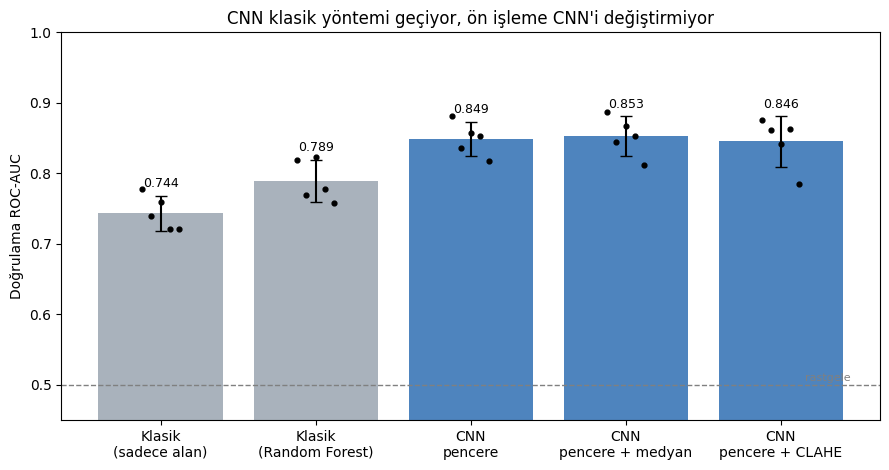

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from google.colab import drive
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

drive.mount("/content/drive")
cikti = "/content/drive/MyDrive/akciger_nodul_LUNA25"
df = pd.read_csv(f"{cikti}/etiketler_bolunmus.csv")
F = pd.read_csv(f"{cikti}/ozellikler.csv")
y, fold = df["label"].values, df["fold"].values
cnn = pd.read_csv(f"{cikti}/cnn_sonuclar.csv")

print(cnn.round(3).to_string(index=False))
print("\nEn iyi epoch ile son epoch arasındaki ortalama fark (seçim iyimserliği):")
print((cnn["en_iyi_auc"] - cnn["son_auc"]).groupby(cnn["kosul"]).mean().round(3))

satirlar = []
for k in range(5):
    eg, dg = (fold != k) & (fold != -1), fold == k
    lr = LogisticRegression(class_weight="balanced").fit(np.log1p(F.loc[eg, ["alan_mm2"]]), y[eg])
    satirlar.append({"kosul": "klasik_alan", "kat": k,
                     "son_auc": roc_auc_score(y[dg], lr.predict_proba(np.log1p(F.loc[dg, ["alan_mm2"]]))[:, 1])})
    rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced",
                                random_state=42, n_jobs=-1).fit(F[eg], y[eg])
    satirlar.append({"kosul": "klasik_rf", "kat": k,
                     "son_auc": roc_auc_score(y[dg], rf.predict_proba(F[dg])[:, 1])})

sira = ["klasik_alan", "klasik_rf", "pencere", "medyan", "clahe"]
tablo = pd.concat([cnn[["kosul", "kat", "son_auc"]], pd.DataFrame(satirlar)]) \
          .pivot(index="kat", columns="kosul", values="son_auc")[sira]
print("\nKat bazında ROC-AUC:")
print(tablo.round(3))

print("\nAynı kattaki eşleştirilmiş farklar:")
for a, b in [("medyan", "pencere"), ("clahe", "pencere"), ("pencere", "klasik_rf"), ("klasik_rf", "klasik_alan")]:
    d = tablo[a] - tablo[b]
    print(f"{a} − {b}: ortalama {d.mean():+.3f} | {(d > 0).sum()}/5 katta pozitif")

ad = {"klasik_alan": "Klasik\n(sadece alan)", "klasik_rf": "Klasik\n(Random Forest)",
      "pencere": "CNN\npencere", "medyan": "CNN\npencere + medyan", "clahe": "CNN\npencere + CLAHE"}
ort, ss = tablo.mean(), tablo.std()
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.bar(range(5), ort, yerr=ss, capsize=4, color=["#9aa5b1"] * 2 + ["#2f6fb3"] * 3, alpha=0.85)
for j, s in enumerate(sira):
    ax.scatter(j + np.linspace(-0.12, 0.12, 5), tablo[s], color="black", s=12, zorder=3)
    ax.text(j, ort[s] + ss[s] + 0.012, f"{ort[s]:.3f}", ha="center", fontsize=9)
ax.axhline(0.5, ls="--", color="gray", lw=1)
ax.text(4.45, 0.505, "rastgele", color="gray", fontsize=8, ha="right")
ax.set_xticks(range(5))
ax.set_xticklabels([ad[s] for s in sira])
ax.set_ylim(0.45, 1.0)
ax.set_ylabel("Doğrulama ROC-AUC")
ax.set_title("CNN klasik yöntemi geçiyor, ön işleme CNN'i değiştirmiyor")
plt.tight_layout()
plt.savefig(f"{cikti}/sunum_gorselleri/11_model_karsilastirma.png", dpi=150)
plt.show()

## Adım 22 — Kilitli test setinde ilk ölçüm (CNN, klasik)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Cihaz: cuda
Youden eşiği: 0.007 (doğrulamada duyarlılık 0.789, özgüllük 0.753)
%90 duyarlılık eşiği: 0.001 (doğrulamada duyarlılık 0.901, özgüllük 0.560)
Kat 0 modeli tek başına test AUC: 0.834
Kat 1 modeli tek başına test AUC: 0.851
Kat 2 modeli tek başına test AUC: 0.891
Kat 3 modeli tek başına test AUC: 0.868
Kat 4 modeli tek başına test AUC: 0.876

TEST SETİ: 1177 kayıt, 110 malign, 424 hasta
                   Model  ROC-AUC %95 güven aralığı  PR-AUC
CNN (5 model ortalaması)    0.888       0.839–0.931   0.530
    Klasik Random Forest    0.839       0.799–0.882   0.421
      Klasik sadece alan    0.749       0.667–0.819   0.320

CNN, Youden (dengeli) eşiği 0.007: TP=103 FN=7 FP=345 TN=722
Duyarlılık 0.936 | Özgüllük 0.677 | Kesinlik 0.230 | F1 0.369 | Doğruluk 0.701

CNN, %90 duyarlılık eşiği 0.001: TP=106 FN=4 FP=628 TN=439
Duyarlılık 0.964 | Özgüllük 0.

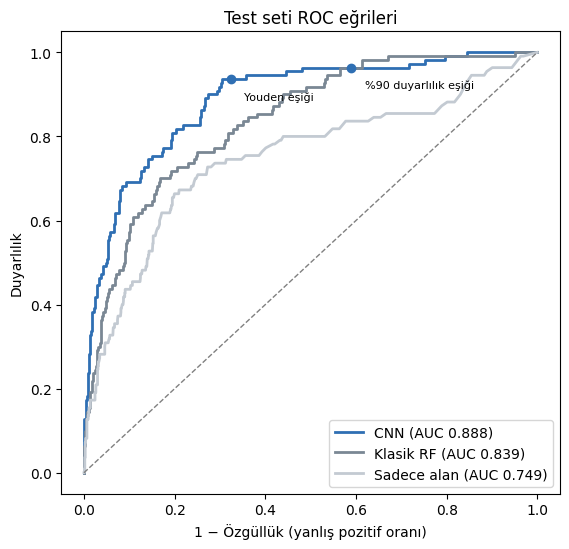

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torchvision
import torchvision.transforms.v2 as T
from torch.utils.data import Dataset, DataLoader
from google.colab import drive
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, confusion_matrix
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

drive.mount("/content/drive")
cikti = "/content/drive/MyDrive/akciger_nodul_LUNA25"
X_pencere = np.load(f"{cikti}/X_pencere.npy")
df = pd.read_csv(f"{cikti}/etiketler_bolunmus.csv")
F = pd.read_csv(f"{cikti}/ozellikler.csv")
y, fold = df["label"].values, df["fold"].values
cihaz = "cuda" if torch.cuda.is_available() else "cpu"
print("Cihaz:", cihaz)

deg_donusum = T.Compose([T.Resize(224, antialias=True),
                         T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

class NodulVeriSeti(Dataset):
    def __init__(self, X, donusum):
        self.X, self.donusum = X, donusum
    def __len__(self):
        return len(self.X)
    def __getitem__(self, i):
        return self.donusum(torch.from_numpy(self.X[i]).float() / 255.0)

def model_yukle(yol):
    m = torchvision.models.resnet18(weights=None)
    m.fc = nn.Linear(m.fc.in_features, 1)
    m.load_state_dict(torch.load(yol, map_location="cpu"))
    return m.float().to(cihaz).eval()

@torch.no_grad()
def tahmin(model, X):
    P = []
    for x in DataLoader(NodulVeriSeti(X, deg_donusum), batch_size=128, num_workers=2):
        with torch.autocast(device_type="cuda", enabled=(cihaz == "cuda")):
            P.append(torch.sigmoid(model(x.to(cihaz))).float().cpu())
    return torch.cat(P).squeeze(1).numpy()

# 1) Karar eşikleri: SADECE doğrulama tahminlerinden
oof = np.zeros(len(df))
for k in range(5):
    oof[np.where(fold == k)[0]] = np.load(f"{cikti}/oof/pencere_kat{k}.npy")
gel = fold != -1
fpr, tpr, esikler = roc_curve(y[gel], oof[gel])

iy = np.argmax(tpr - fpr)
esik = esikler[iy]
print(f"Youden eşiği: {esik:.3f} (doğrulamada duyarlılık {tpr[iy]:.3f}, özgüllük {1 - fpr[iy]:.3f})")

i90 = np.argmax(tpr >= 0.90)
esik90 = esikler[i90]
print(f"%90 duyarlılık eşiği: {esik90:.3f} (doğrulamada duyarlılık {tpr[i90]:.3f}, özgüllük {1 - fpr[i90]:.3f})")

# 2) Test seti: CNN (5 kat modelinin ortalaması)
test = np.where(fold == -1)[0]
Xt, yt = X_pencere[test], y[test]
P = np.stack([tahmin(model_yukle(f"{cikti}/modeller/pencere_kat{k}.pt"), Xt) for k in range(5)])
for k in range(5):
    print(f"Kat {k} modeli tek başına test AUC: {roc_auc_score(yt, P[k]):.3f}")
p_cnn = P.mean(axis=0)
np.save(f"{cikti}/test_tahmin_cnn.npy", p_cnn)

# 3) Test seti: klasik yöntemler (geliştirme verisinin tamamıyla eğitilir)
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced",
                            random_state=42, n_jobs=-1).fit(F[gel], y[gel])
p_rf = rf.predict_proba(F.iloc[test])[:, 1]
lr = LogisticRegression(class_weight="balanced").fit(np.log1p(F.loc[gel, ["alan_mm2"]]), y[gel])
p_alan = lr.predict_proba(np.log1p(F.iloc[test][["alan_mm2"]]))[:, 1]

# 4) Hasta düzeyinde bootstrap ile %95 güven aralığı
hasta_t = df["PatientID"].values[test]
hastalar = np.unique(hasta_t)
gruplar = {h: np.where(hasta_t == h)[0] for h in hastalar}

def bootstrap_auc(p, B=1000):
    rng, d = np.random.default_rng(0), []
    for _ in range(B):
        idx = np.concatenate([gruplar[h] for h in rng.choice(hastalar, len(hastalar))])
        if 0 < yt[idx].sum() < len(idx):
            d.append(roc_auc_score(yt[idx], p[idx]))
    return np.percentile(d, [2.5, 97.5])

satirlar = []
for ad, p in [("CNN (5 model ortalaması)", p_cnn), ("Klasik Random Forest", p_rf), ("Klasik sadece alan", p_alan)]:
    alt, ust = bootstrap_auc(p)
    satirlar.append({"Model": ad, "ROC-AUC": round(roc_auc_score(yt, p), 3),
                     "%95 güven aralığı": f"{alt:.3f}–{ust:.3f}",
                     "PR-AUC": round(average_precision_score(yt, p), 3)})
print(f"\nTEST SETİ: {len(test)} kayıt, {yt.sum()} malign, {len(hastalar)} hasta")
print(pd.DataFrame(satirlar).to_string(index=False))

# 5) CNN, iki eşikte (ikisi de doğrulamadan seçildi)
for ad, e in [("Youden (dengeli)", esik), ("%90 duyarlılık", esik90)]:
    tn, fp, fn, tp = confusion_matrix(yt, (p_cnn >= e).astype(int)).ravel()
    duy, ozg, kes = tp / (tp + fn), tn / (tn + fp), tp / (tp + fp)
    print(f"\nCNN, {ad} eşiği {e:.3f}: TP={tp} FN={fn} FP={fp} TN={tn}")
    print(f"Duyarlılık {duy:.3f} | Özgüllük {ozg:.3f} | Kesinlik {kes:.3f} | "
          f"F1 {2 * kes * duy / (kes + duy):.3f} | Doğruluk {(tp + tn) / len(yt):.3f}")
    if ad.startswith("Youden"):
        duy_y, ozg_y = duy, ozg
    else:
        duy_90, ozg_90 = duy, ozg

# 6) Nodül düzeyinde (aynı nodülün tahminlerinin ortalaması)
nod = pd.DataFrame({"n": df["NoduleID"].values[test], "y": yt, "p": p_cnn}) \
        .groupby("n").agg(y=("y", "first"), p=("p", "mean"))
print(f"\nNodül düzeyinde ROC-AUC: {roc_auc_score(nod.y, nod.p):.3f} ({len(nod)} nodül, {nod.y.sum()} malign)")

# 7) ROC eğrileri
fig, ax = plt.subplots(figsize=(5.8, 5.6))
for ad, p, renk in [("CNN", p_cnn, "#2f6fb3"), ("Klasik RF", p_rf, "#7a8794"), ("Sadece alan", p_alan, "#c3cad2")]:
    f, t, _ = roc_curve(yt, p)
    ax.plot(f, t, color=renk, lw=2, label=f"{ad} (AUC {roc_auc_score(yt, p):.3f})")
ax.plot([0, 1], [0, 1], "--", color="gray", lw=1)
ax.scatter([1 - ozg_y, 1 - ozg_90], [duy_y, duy_90], color="#2f6fb3", zorder=3)
ax.annotate("Youden eşiği", (1 - ozg_y, duy_y), xytext=(10, -15), textcoords="offset points", fontsize=8)
ax.annotate("%90 duyarlılık eşiği", (1 - ozg_90, duy_90), xytext=(10, -15), textcoords="offset points", fontsize=8)
ax.set_xlabel("1 − Özgüllük (yanlış pozitif oranı)")
ax.set_ylabel("Duyarlılık")
ax.set_title("Test seti ROC eğrileri")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(f"{cikti}/sunum_gorselleri/12_test_roc.png", dpi=150)
plt.show()

## Adım 23 — Grad-CAM

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


/tmp/ipykernel_700/3347227135.py:70: RuntimeWarning: invalid value encountered in divide
  oran = (cam_test * genis).sum(axis=(1, 2)) / cam_test.sum(axis=(1, 2))


      sayi  tepe_merkeze_medyan_mm  tepe_10mm_icinde  \
grup                                                   
FN       7                   41.43              0.00   
FP     345                   41.43              0.06   
TN     722                   48.61              0.00   
TP     103                   22.50              0.29   

      nodul_bolgesi_orani_medyan  
grup                              
FN                          0.00  
FP                          0.01  
TN                          0.00  
TP                          0.06  


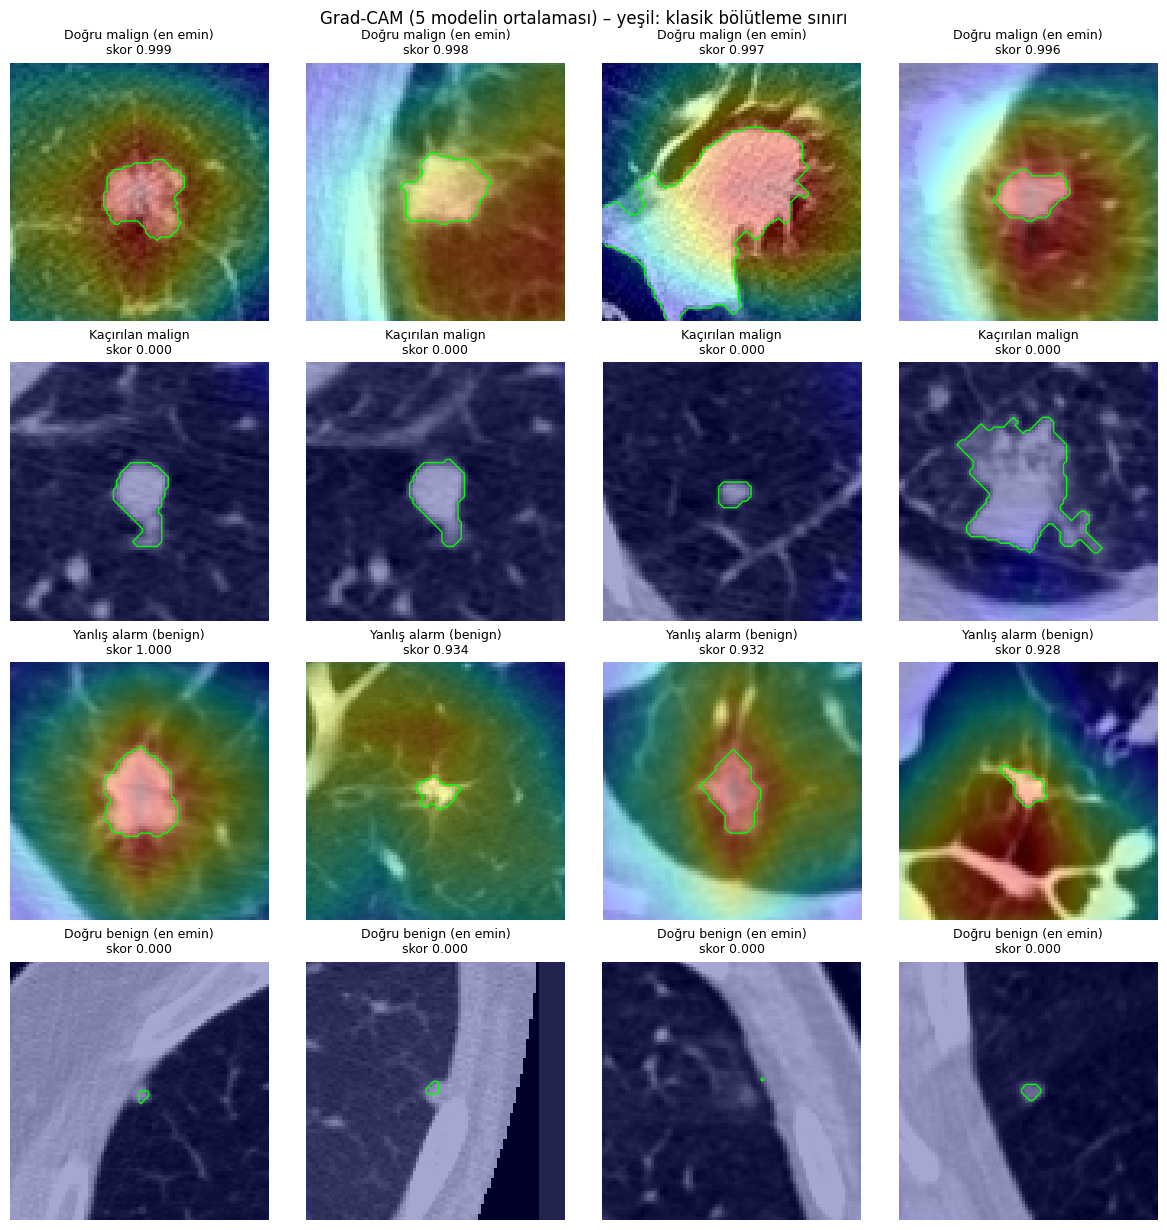

In [3]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as Fnn, torchvision
import torchvision.transforms.v2 as T
from google.colab import drive
from scipy import ndimage
from sklearn.metrics import roc_curve

drive.mount("/content/drive")
cikti = "/content/drive/MyDrive/akciger_nodul_LUNA25"
X_pencere = np.load(f"{cikti}/X_pencere.npy")
df = pd.read_csv(f"{cikti}/etiketler_bolunmus.csv")
maskeler = np.load(f"{cikti}/maskeler.npz")["maskeler"]
p_cnn = np.load(f"{cikti}/test_tahmin_cnn.npy")
y, fold = df["label"].values, df["fold"].values
test = np.where(fold == -1)[0]
yt = y[test]
cihaz = "cuda" if torch.cuda.is_available() else "cpu"

on_isle = T.Compose([T.Resize(224, antialias=True),
                     T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

def model_yukle(yol):
    m = torchvision.models.resnet18(weights=None)
    m.fc = nn.Linear(m.fc.in_features, 1)
    m.load_state_dict(torch.load(yol, map_location="cpu"))
    return m.float().to(cihaz).eval()

modeller = [model_yukle(f"{cikti}/modeller/pencere_kat{k}.pt") for k in range(5)]

def gradcam_batch(model, x):
    kayit = {}
    def ileri(modul, girdi, cikis):
        kayit["a"] = cikis
        cikis.register_hook(lambda g: kayit.__setitem__("g", g))
    kanca = model.layer4[-1].register_forward_hook(ileri)
    model.zero_grad(set_to_none=True)
    model(x).sum().backward()
    kanca.remove()
    w = kayit["g"].mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((w * kayit["a"]).sum(dim=1, keepdim=True))
    cam = Fnn.interpolate(cam, size=(128, 128), mode="bilinear", align_corners=False)[:, 0]
    cam = cam / (cam.amax(dim=(1, 2), keepdim=True) + 1e-8)
    return cam.detach().cpu().numpy()

def gradcam_ensemble(idx, batch=64):
    sonuc = np.zeros((len(idx), 128, 128), dtype=np.float32)
    for s in range(0, len(idx), batch):
        x = torch.stack([on_isle(torch.from_numpy(X_pencere[i]).float() / 255)
                         for i in idx[s:s + batch]]).to(cihaz)
        sonuc[s:s + batch] = np.mean([gradcam_batch(m, x) for m in modeller], axis=0)
    return sonuc

cam_test = gradcam_ensemble(test)
np.save(f"{cikti}/test_gradcam.npy", cam_test.astype(np.float16))

# Youden eşiği (Adım 22 ile aynı hesap)
oof = np.zeros(len(df))
for k in range(5):
    oof[np.where(fold == k)[0]] = np.load(f"{cikti}/oof/pencere_kat{k}.npy")
fpr, tpr, esikler = roc_curve(y[fold != -1], oof[fold != -1])
esik = esikler[np.argmax(tpr - fpr)]
tahmin_sinif = (p_cnn >= esik).astype(int)
grup = np.select([(yt == 1) & (tahmin_sinif == 1), (yt == 1) & (tahmin_sinif == 0),
                  (yt == 0) & (tahmin_sinif == 1)], ["TP", "FN", "FP"], default="TN")

# Nicel kontrol: ısı haritası nodülün üzerinde mi?
tepe = np.array([np.unravel_index(c.argmax(), c.shape) for c in cam_test])
uzaklik_mm = np.hypot(tepe[:, 0] - 64, tepe[:, 1] - 64) * 0.625
genis = np.stack([ndimage.binary_dilation(maskeler[i], iterations=5) for i in test])
oran = (cam_test * genis).sum(axis=(1, 2)) / cam_test.sum(axis=(1, 2))
ozet = pd.DataFrame({"grup": grup, "tepe_merkeze_mm": uzaklik_mm,
                     "10mm_icinde": uzaklik_mm <= 10, "nodul_bolgesi_orani": oran})
print(ozet.groupby("grup").agg(sayi=("grup", "size"),
                              tepe_merkeze_medyan_mm=("tepe_merkeze_mm", "median"),
                              tepe_10mm_icinde=("10mm_icinde", "mean"),
                              nodul_bolgesi_orani_medyan=("nodul_bolgesi_orani", "median")).round(2))

# Görsel: her gruptan 4 örnek
sec = {"TP": test[yt == 1][np.argsort(-p_cnn[yt == 1])[:4]],
       "FN": test[yt == 1][np.argsort(p_cnn[yt == 1])[:4]],
       "FP": test[yt == 0][np.argsort(-p_cnn[yt == 0])[:4]],
       "TN": test[yt == 0][np.argsort(p_cnn[yt == 0])[:4]]}
aciklama = {"TP": "Doğru malign (en emin)", "FN": "Kaçırılan malign",
            "FP": "Yanlış alarm (benign)", "TN": "Doğru benign (en emin)"}
konum = {i: j for j, i in enumerate(test)}
kirp = slice(24, 104)
fig, axes = plt.subplots(4, 4, figsize=(12, 12.5))
for satir, (g, idx) in enumerate(sec.items()):
    for j, i in enumerate(idx):
        ax = axes[satir, j]
        ax.imshow(X_pencere[i, 1, kirp, kirp], cmap="gray")
        ax.imshow(cam_test[konum[i]][kirp, kirp], cmap="jet", alpha=0.35, vmin=0, vmax=1)
        ax.contour(maskeler[i][kirp, kirp], levels=[0.5], colors="lime", linewidths=1)
        ax.set_title(f"{aciklama[g]}\nskor {p_cnn[konum[i]]:.3f}", fontsize=9)
        ax.axis("off")
plt.suptitle("Grad-CAM (5 modelin ortalaması) – yeşil: klasik bölütleme sınırı", fontsize=12)
plt.tight_layout()
plt.savefig(f"{cikti}/sunum_gorselleri/13_gradcam.png", dpi=150)
plt.show()

## Adım 23b — Grad-CAM nicel ölçüm (düzeltilmiş sürüm)

Isı haritası tamamen boş olan görüntüler (malign yönünde kanıt yok):
      sum  size
grup           
FN      0     7
FP      0   345
TN     48   722
TP      0   103

Boş olmayan haritalarda:
      sayi  agirlik_merkezi_merkeze_mm  odak_orani_medyan  odak_1den_buyuk
grup                                                                      
FN       7                       30.75               0.00             0.00
FP     345                       17.80               0.31             0.35
TN     674                       32.51               0.00             0.02
TP     103                       10.38               2.43             0.77


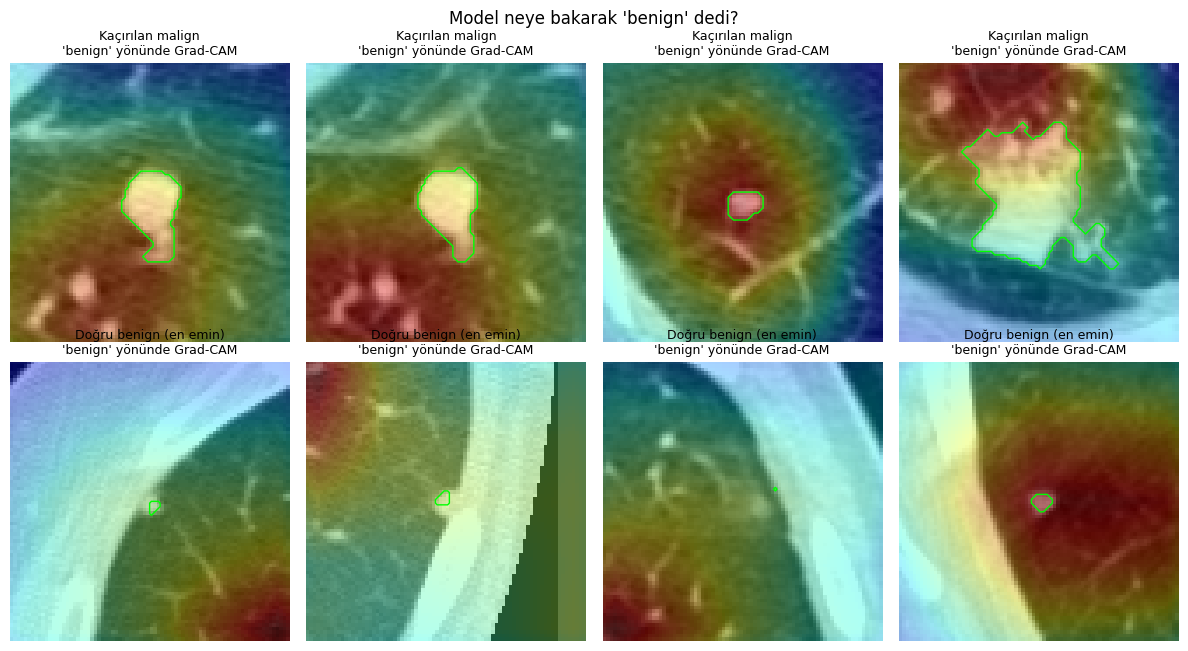

In [4]:
# 1) Düzeltilmiş nicel ölçüm
toplam = cam_test.sum(axis=(1, 2))
dolu = toplam > 1e-6
print("Isı haritası tamamen boş olan görüntüler (malign yönünde kanıt yok):")
print(pd.DataFrame({"grup": grup, "bos": ~dolu}).groupby("grup")["bos"].agg(["sum", "size"]))

yy, xx = np.mgrid[:128, :128]
ay = (cam_test * yy).sum(axis=(1, 2)) / np.maximum(toplam, 1e-8)
ax_ = (cam_test * xx).sum(axis=(1, 2)) / np.maximum(toplam, 1e-8)
merkez_mm = np.hypot(ay - 64, ax_ - 64) * 0.625
odak = ((cam_test * genis).sum(axis=(1, 2)) / genis.sum(axis=(1, 2))) \
       / np.maximum(cam_test.mean(axis=(1, 2)), 1e-8)

d = pd.DataFrame({"grup": grup, "merkez_mm": merkez_mm, "odak": odak})[dolu]
print("\nBoş olmayan haritalarda:")
print(d.groupby("grup").agg(sayi=("grup", "size"),
                            agirlik_merkezi_merkeze_mm=("merkez_mm", "median"),
                            odak_orani_medyan=("odak", "median"),
                            odak_1den_buyuk=("odak", lambda s: (s > 1).mean())).round(2))

# 2) "Benign" yönünde Grad-CAM: model neye bakarak benign dedi?
def gradcam_batch(model, x, yon=1.0):
    kayit = {}
    def ileri(modul, girdi, cikis):
        kayit["a"] = cikis
        cikis.register_hook(lambda g: kayit.__setitem__("g", g))
    kanca = model.layer4[-1].register_forward_hook(ileri)
    model.zero_grad(set_to_none=True)
    (yon * model(x)).sum().backward()
    kanca.remove()
    w = kayit["g"].mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((w * kayit["a"]).sum(dim=1, keepdim=True))
    cam = Fnn.interpolate(cam, size=(128, 128), mode="bilinear", align_corners=False)[:, 0]
    cam = cam / (cam.amax(dim=(1, 2), keepdim=True) + 1e-8)
    return cam.detach().cpu().numpy()

def benign_cam(idx):
    x = torch.stack([on_isle(torch.from_numpy(X_pencere[i]).float() / 255) for i in idx]).to(cihaz)
    return np.mean([gradcam_batch(m, x, yon=-1.0) for m in modeller], axis=0)

fig, axes = plt.subplots(2, 4, figsize=(12, 6.6))
for satir, g in enumerate(["FN", "TN"]):
    camb = benign_cam(sec[g])
    for j, i in enumerate(sec[g]):
        ax = axes[satir, j]
        ax.imshow(X_pencere[i, 1, kirp, kirp], cmap="gray")
        ax.imshow(camb[j][kirp, kirp], cmap="jet", alpha=0.35, vmin=0, vmax=1)
        ax.contour(maskeler[i][kirp, kirp], levels=[0.5], colors="lime", linewidths=1)
        ax.set_title(f"{aciklama[g]}\n'benign' yönünde Grad-CAM", fontsize=9)
        ax.axis("off")
plt.suptitle("Model neye bakarak 'benign' dedi?", fontsize=12)
plt.tight_layout()
plt.savefig(f"{cikti}/sunum_gorselleri/14_gradcam_benign.png", dpi=150)
plt.show()

## Adım 24 (ilk deneme) — Ezber/düzenleme deneyi
Oturum sıfırlandığı için bu hücre hata verdi; tam hali bir sonraki hücrede.

In [5]:
def egit_duzenli(X, k, epoch=4, lr=3e-4, yumusatma=0.1, dropout=0.3):
    torch.manual_seed(42)
    egl, dgl = yukleyiciler(X, k)
    model = model_kur()
    model.fc = nn.Sequential(nn.Dropout(dropout), nn.Linear(512, 1)).to(cihaz)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    zamanlayici = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epoch)
    kayip_f = nn.BCEWithLogitsLoss()
    olcek = torch.amp.GradScaler()
    for e in range(epoch):
        model.train()
        toplam, n = 0.0, 0
        for x, yb in egl:
            x, yb = x.to(cihaz), yb.to(cihaz)
            hedef = yb * (1 - yumusatma) + 0.5 * yumusatma
            opt.zero_grad()
            with torch.autocast("cuda"):
                kayip = kayip_f(model(x).squeeze(1), hedef)
            olcek.scale(kayip).backward()
            olcek.step(opt)
            olcek.update()
            toplam += kayip.item() * len(yb)
            n += len(yb)
        zamanlayici.step()
        p, yd = tahmin(model, dgl)
        print(f"  kat {k} | epoch {e + 1} | eğitim kaybı {toplam / n:.3f} | doğrulama AUC {roc_auc_score(yd, p):.3f}")
    torch.save({a: (b.half() if b.is_floating_point() else b).cpu() for a, b in model.state_dict().items()},
               f"{cikti}/modeller/duzenli_kat{k}.pt")
    return roc_auc_score(yd, p), average_precision_score(yd, p), p

eski = pd.read_csv(f"{cikti}/cnn_sonuclar.csv").query("kosul == 'pencere'").sort_values("kat")
satirlar, oof_eski, oof_yeni = [], np.zeros(len(df)), np.zeros(len(df))
for k in range(5):
    auc, pr, p = egit_duzenli(X_pencere, k)
    idx = np.where(fold == k)[0]
    oof_yeni[idx] = p
    oof_eski[idx] = np.load(f"{cikti}/oof/pencere_kat{k}.npy")
    np.save(f"{cikti}/oof/duzenli_kat{k}.npy", p)
    satirlar.append({"kat": k, "eski_auc": eski["son_auc"].iloc[k], "yeni_auc": auc,
                     "eski_pr_auc": eski["son_pr_auc"].iloc[k], "yeni_pr_auc": pr})
t = pd.DataFrame(satirlar)
t.to_csv(f"{cikti}/cnn_sonuclar_duzenli.csv", index=False)
print(t.round(3).to_string(index=False))
print(t[["eski_auc", "yeni_auc", "eski_pr_auc", "yeni_pr_auc"]].agg(["mean", "std"]).round(3))
print(f"Yeni − eski AUC: {(t.yeni_auc - t.eski_auc).mean():+.3f} | {(t.yeni_auc > t.eski_auc).sum()}/5 katta yeni daha iyi")

gel = fold != -1
for ad, o in [("Eski (12 epoch)", oof_eski), ("Düzenli (4 epoch + yumuşatma + dropout)", oof_yeni)]:
    fpr, tpr, es = roc_curve(y[gel], o[gel])
    i = np.argmax(tpr - fpr)
    print(f"{ad}: Youden eşiği {es[i]:.3f} | malign skor medyanı {np.median(o[gel & (y == 1)]):.3f} "
          f"| benign skor medyanı {np.median(o[gel & (y == 0)]):.3f}")

NameError: name 'yukleyiciler' is not defined

## Adım 24 — Ezber/düzenleme deneyi (4 epoch, etiket yumuşatma, dropout)
Sonuç: düzenleme 5/5 katta AUC'yi düşürdü; asıl model korundu.

In [6]:
import os, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torchvision
import torchvision.transforms.v2 as T
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from google.colab import drive
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve

# ---------- Yükleme ----------
drive.mount("/content/drive")
cikti = "/content/drive/MyDrive/akciger_nodul_LUNA25"
X_pencere = np.load(f"{cikti}/X_pencere.npy")
df = pd.read_csv(f"{cikti}/etiketler_bolunmus.csv")
y, fold, N = df["label"].values, df["fold"].values, len(df)
assert (np.load(f"{cikti}/annotation_ids.npy") == df["AnnotationID"].values).all()
cihaz = "cuda" if torch.cuda.is_available() else "cpu"
print("Cihaz:", cihaz, "| Veri:", X_pencere.shape)

# ---------- Veri ----------
ORT, SS = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
egitim_donusum = T.Compose([
    T.RandomHorizontalFlip(), T.RandomVerticalFlip(),
    T.RandomApply([T.RandomRotation((90, 90))], p=0.5),
    T.Resize(224, antialias=True), T.Normalize(ORT, SS)])
deg_donusum = T.Compose([T.Resize(224, antialias=True), T.Normalize(ORT, SS)])

class NodulVeriSeti(Dataset):
    def __init__(self, X, y, donusum):
        self.X, self.y, self.donusum = X, y, donusum
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        x = torch.from_numpy(self.X[i]).float() / 255.0
        return self.donusum(x), torch.tensor(self.y[i], dtype=torch.float32)

goruntu_say = df.groupby("NoduleID")["AnnotationID"].transform("count").values

def yukleyiciler(X, k, batch=64):
    eg = np.where((fold != k) & (fold != -1))[0]
    dg = np.where(fold == k)[0]
    nodul_say = df.iloc[eg].groupby("label")["NoduleID"].nunique()
    w = 1.0 / (nodul_say.loc[y[eg]].values * goruntu_say[eg])
    ornekleyici = WeightedRandomSampler(torch.as_tensor(w, dtype=torch.double),
                                        num_samples=len(eg), replacement=True)
    egl = DataLoader(NodulVeriSeti(X[eg], y[eg], egitim_donusum), batch_size=batch,
                     sampler=ornekleyici, num_workers=2, pin_memory=True)
    dgl = DataLoader(NodulVeriSeti(X[dg], y[dg], deg_donusum), batch_size=128,
                     shuffle=False, num_workers=2, pin_memory=True)
    return egl, dgl

# ---------- Model ----------
def model_kur():
    m = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
    m.fc = nn.Linear(m.fc.in_features, 1)
    return m.to(cihaz)

@torch.no_grad()
def tahmin(model, yukleyici):
    model.eval()
    P, Y = [], []
    for x, yb in yukleyici:
        with torch.autocast("cuda"):
            P.append(torch.sigmoid(model(x.to(cihaz))).float().cpu())
        Y.append(yb)
    return torch.cat(P).squeeze(1).numpy(), torch.cat(Y).numpy()

# ---------- Düzenlenmiş eğitim ----------
def egit_duzenli(X, k, epoch=4, lr=3e-4, yumusatma=0.1, dropout=0.3):
    torch.manual_seed(42)
    egl, dgl = yukleyiciler(X, k)
    model = model_kur()
    model.fc = nn.Sequential(nn.Dropout(dropout), nn.Linear(512, 1)).to(cihaz)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    zamanlayici = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epoch)
    kayip_f = nn.BCEWithLogitsLoss()
    olcek = torch.amp.GradScaler()
    for e in range(epoch):
        model.train()
        toplam, n = 0.0, 0
        for x, yb in egl:
            x, yb = x.to(cihaz), yb.to(cihaz)
            hedef = yb * (1 - yumusatma) + 0.5 * yumusatma
            opt.zero_grad()
            with torch.autocast("cuda"):
                kayip = kayip_f(model(x).squeeze(1), hedef)
            olcek.scale(kayip).backward()
            olcek.step(opt)
            olcek.update()
            toplam += kayip.item() * len(yb)
            n += len(yb)
        zamanlayici.step()
        p, yd = tahmin(model, dgl)
        print(f"  kat {k} | epoch {e + 1} | eğitim kaybı {toplam / n:.3f} | doğrulama AUC {roc_auc_score(yd, p):.3f}")
    torch.save({a: (b.half() if b.is_floating_point() else b).cpu() for a, b in model.state_dict().items()},
               f"{cikti}/modeller/duzenli_kat{k}.pt")
    return roc_auc_score(yd, p), average_precision_score(yd, p), p

# ---------- 5 kat ----------
eski = pd.read_csv(f"{cikti}/cnn_sonuclar.csv").query("kosul == 'pencere'").sort_values("kat")
satirlar, oof_eski, oof_yeni = [], np.zeros(N), np.zeros(N)
for k in range(5):
    auc, pr, p = egit_duzenli(X_pencere, k)
    idx = np.where(fold == k)[0]
    oof_yeni[idx] = p
    oof_eski[idx] = np.load(f"{cikti}/oof/pencere_kat{k}.npy")
    np.save(f"{cikti}/oof/duzenli_kat{k}.npy", p)
    satirlar.append({"kat": k, "eski_auc": eski["son_auc"].iloc[k], "yeni_auc": auc,
                     "eski_pr_auc": eski["son_pr_auc"].iloc[k], "yeni_pr_auc": pr})

t = pd.DataFrame(satirlar)
t.to_csv(f"{cikti}/cnn_sonuclar_duzenli.csv", index=False)
print("\n", t.round(3).to_string(index=False))
print(t[["eski_auc", "yeni_auc", "eski_pr_auc", "yeni_pr_auc"]].agg(["mean", "std"]).round(3))
print(f"Yeni − eski AUC: {(t.yeni_auc - t.eski_auc).mean():+.3f} | "
      f"{(t.yeni_auc > t.eski_auc).sum()}/5 katta yeni daha iyi")

# ---------- Skorlar ne kadar aşırı emin? ----------
gel = fold != -1
for ad, o in [("Eski (12 epoch)", oof_eski), ("Düzenli (4 epoch + yumuşatma + dropout)", oof_yeni)]:
    fpr, tpr, es = roc_curve(y[gel], o[gel])
    i = np.argmax(tpr - fpr)
    print(f"{ad}: Youden eşiği {es[i]:.3f} | malign skor medyanı {np.median(o[gel & (y == 1)]):.3f} "
          f"| benign skor medyanı {np.median(o[gel & (y == 0)]):.3f}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Cihaz: cuda | Veri: (6163, 3, 128, 128)
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 66.4MB/s]


  kat 0 | epoch 1 | eğitim kaybı 0.524 | doğrulama AUC 0.863
  kat 0 | epoch 2 | eğitim kaybı 0.412 | doğrulama AUC 0.841
  kat 0 | epoch 3 | eğitim kaybı 0.342 | doğrulama AUC 0.876
  kat 0 | epoch 4 | eğitim kaybı 0.312 | doğrulama AUC 0.865
  kat 1 | epoch 1 | eğitim kaybı 0.536 | doğrulama AUC 0.851
  kat 1 | epoch 2 | eğitim kaybı 0.407 | doğrulama AUC 0.852
  kat 1 | epoch 3 | eğitim kaybı 0.354 | doğrulama AUC 0.803
  kat 1 | epoch 4 | eğitim kaybı 0.309 | doğrulama AUC 0.803
  kat 2 | epoch 1 | eğitim kaybı 0.543 | doğrulama AUC 0.869
  kat 2 | epoch 2 | eğitim kaybı 0.422 | doğrulama AUC 0.861
  kat 2 | epoch 3 | eğitim kaybı 0.349 | doğrulama AUC 0.870
  kat 2 | epoch 4 | eğitim kaybı 0.308 | doğrulama AUC 0.854
  kat 3 | epoch 1 | eğitim kaybı 0.525 | doğrulama AUC 0.835
  kat 3 | epoch 2 | eğitim kaybı 0.410 | doğrulama AUC 0.842
  kat 3 | epoch 3 | eğitim kaybı 0.357 | doğrulama AUC 0.833
  kat 3 | epoch 4 | eğitim kaybı 0.307 | doğrulama AUC 0.822
  kat 4 | epoch 1 | eğit

## Adım 25 — Medyan filtrenin klasik yönteme etkisi (filtreli / filtresiz bölütleme)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


  0%|          | 0/6163 [00:00<?, ?it/s]

İki bölütlemenin örtüşmesi (IoU) medyan: 0.99 | IoU < 0,5 olan nodül: 180
Medyan filtreli: 1–4 piksellik maske 474 | medyan alan benign 36, malign 155 piksel
Filtresiz: 1–4 piksellik maske 452 | medyan alan benign 36, malign 149 piksel

  kat  medyan_auc  filtresiz_auc  medyan_pr  filtresiz_pr
   0       0.818          0.812      0.329         0.329
   1       0.769          0.764      0.276         0.239
   2       0.824          0.827      0.375         0.361
   3       0.778          0.792      0.258         0.266
   4       0.758          0.751      0.323         0.310
      medyan_auc  filtresiz_auc  medyan_pr  filtresiz_pr
mean       0.789          0.789      0.312         0.301
std        0.030          0.032      0.046         0.049
Medyan − filtresiz AUC: +0.000 | 3/5 katta medyan daha iyi


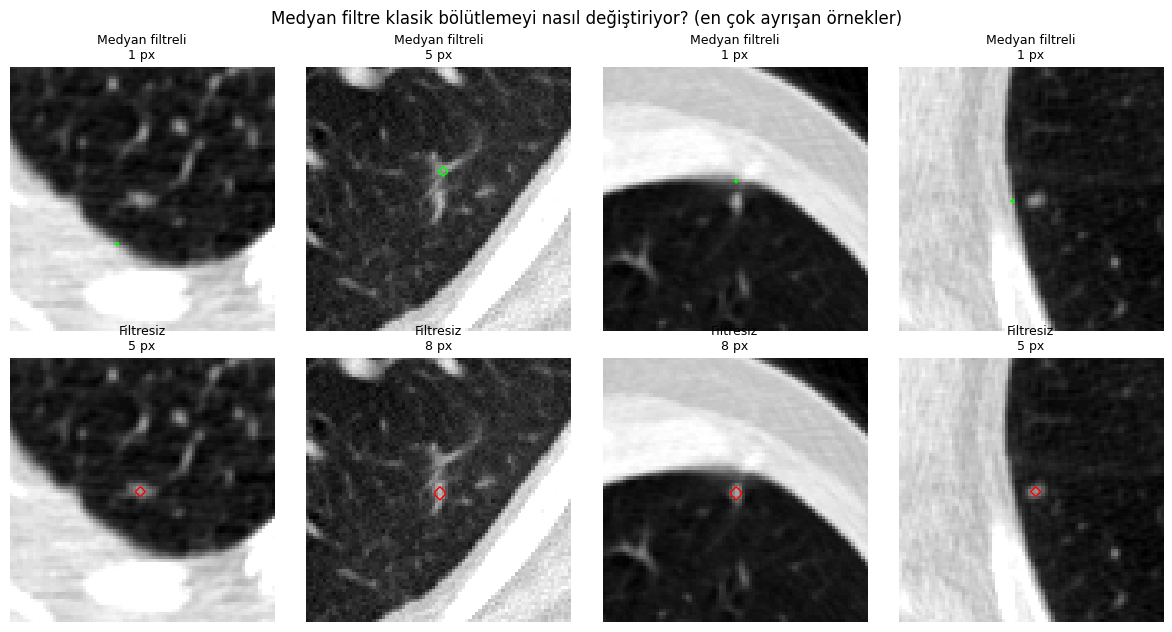

In [7]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from google.colab import drive
from scipy import ndimage
from skimage.filters import threshold_otsu, sobel
from skimage.measure import label, regionprops
from skimage.morphology import disk
from skimage.segmentation import watershed
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score
from tqdm.auto import tqdm

drive.mount("/content/drive")
cikti = "/content/drive/MyDrive/akciger_nodul_LUNA25"
X_pencere = np.load(f"{cikti}/X_pencere.npy")
df = pd.read_csv(f"{cikti}/etiketler_bolunmus.csv")
y, fold, N = df["label"].values, df["fold"].values, len(df)
F_medyan = pd.read_csv(f"{cikti}/ozellikler.csv")
maskeler_medyan = np.load(f"{cikti}/maskeler.npz")["maskeler"]

# Adım 16–18 ile aynı bölütleme ve özellikler
KENAR = np.zeros((128, 128), dtype=bool)
KENAR[[0, -1], :] = True
KENAR[:, [0, -1]] = True
yy, xx = np.mgrid[:128, :128]
MERKEZE_UZAKLIK = np.hypot(yy - 64, xx - 64)

def morf(A, islem, r):
    p = r + 1
    return islem(np.pad(A, p, mode="edge"), structure=disk(r))[p:-p, p:-p]

def bolutle_ws(k):
    esik = threshold_otsu(k[32:96, 32:96])
    acik = morf(k > esik, ndimage.binary_opening, 1)
    kapali = ndimage.binary_fill_holes(morf(acik, ndimage.binary_closing, 2))
    if not kapali.any():
        return kapali
    uz = np.where(kapali, MERKEZE_UZAKLIK, np.inf)
    ty, tx = np.unravel_index(np.argmin(uz), uz.shape)
    isaret = np.zeros((128, 128), dtype=int)
    isaret[KENAR & kapali] = 2
    isaret[ty, tx] = 1
    return watershed(-ndimage.distance_transform_edt(kapali), isaret, mask=kapali) == 1

def ozellikler(m, kesit):
    k = kesit.astype(np.float32)
    hu = k / 255 * 1500 - 1350
    r = regionprops(m.astype(int))[0]
    cevre_px = max(r.perimeter, 1)
    sinir = m & ~ndimage.binary_erosion(m, structure=disk(1))
    return {"alan_mm2": r.area * 0.625 ** 2, "esdeger_cap_mm": r.equivalent_diameter_area * 0.625,
            "dairesellik": 4 * np.pi * r.area / cevre_px ** 2, "doluluk": r.solidity,
            "eksantriklik": r.eccentricity, "ort_hu": hu[m].mean(), "std_hu": hu[m].std(),
            "kalsifikasyon_orani": (k[m] >= 254).mean(), "kenar_gradyani": sobel(k / 255)[sinir].mean()}

# Filtresiz bölütleme + özellikler
maskeler_ham = np.zeros_like(maskeler_medyan)
satirlar = []
for i in tqdm(range(N)):
    m = bolutle_ws(X_pencere[i, 1].astype(np.float32) / 255)
    if not m.any():
        m[64, 64] = True
    maskeler_ham[i] = m
    satirlar.append(ozellikler(m, X_pencere[i, 1]))
F_ham = pd.DataFrame(satirlar)
F_ham.to_csv(f"{cikti}/ozellikler_filtresiz.csv", index=False)

# 1) Bölütleme ne kadar değişti?
kesisim = (maskeler_medyan & maskeler_ham).sum(axis=(1, 2))
birlesim = (maskeler_medyan | maskeler_ham).sum(axis=(1, 2))
iou = kesisim / np.maximum(birlesim, 1)
print(f"İki bölütlemenin örtüşmesi (IoU) medyan: {np.median(iou):.2f} | IoU < 0,5 olan nodül: {(iou < 0.5).sum()}")
for ad, M in [("Medyan filtreli", maskeler_medyan), ("Filtresiz", maskeler_ham)]:
    alan = M.sum(axis=(1, 2))
    print(f"{ad}: 1–4 piksellik maske {(alan < 5).sum()} | medyan alan benign {np.median(alan[y == 0]):.0f}, "
          f"malign {np.median(alan[y == 1]):.0f} piksel")

# 2) Random Forest, aynı 5 kat
def rf_cv(F):
    auc, pr = [], []
    for k in range(5):
        eg, dg = (fold != k) & (fold != -1), fold == k
        rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced",
                                    random_state=42, n_jobs=-1).fit(F[eg], y[eg])
        p = rf.predict_proba(F[dg])[:, 1]
        auc.append(roc_auc_score(y[dg], p))
        pr.append(average_precision_score(y[dg], p))
    return np.array(auc), np.array(pr)

a_m, p_m = rf_cv(F_medyan)
a_h, p_h = rf_cv(F_ham)
t = pd.DataFrame({"kat": range(5), "medyan_auc": a_m, "filtresiz_auc": a_h,
                  "medyan_pr": p_m, "filtresiz_pr": p_h})
print("\n", t.round(3).to_string(index=False))
print(t.drop(columns="kat").agg(["mean", "std"]).round(3))
print(f"Medyan − filtresiz AUC: {(a_m - a_h).mean():+.3f} | {(a_m > a_h).sum()}/5 katta medyan daha iyi")

# 3) Görsel: iki bölütlemenin en çok ayrıştığı 4 nodül
sec = np.argsort(iou)[:4]
kirp = slice(24, 104)
fig, axes = plt.subplots(2, 4, figsize=(12, 6.4))
for j, i in enumerate(sec):
    for satir, (ad, M) in enumerate([("Medyan filtreli", maskeler_medyan), ("Filtresiz", maskeler_ham)]):
        ax = axes[satir, j]
        ax.imshow(X_pencere[i, 1, kirp, kirp], cmap="gray")
        ax.contour(M[i][kirp, kirp], levels=[0.5], colors="lime" if satir == 0 else "red", linewidths=1)
        ax.set_title(f"{ad}\n{M[i].sum()} px", fontsize=9)
        ax.axis("off")
plt.suptitle("Medyan filtre klasik bölütlemeyi nasıl değiştiriyor? (en çok ayrışan örnekler)")
plt.tight_layout()
plt.savefig(f"{cikti}/sunum_gorselleri/15_filtre_bolutleme.png", dpi=150)
plt.show()